# 🎤 Reconnaissance des Émotions Vocales (SER) — RAVDESS

**Comparaison de 3 approches : CNN 2D · LSTM · Wav2Vec2 (fine-tuning)**

Ce notebook est organisé en sections indépendantes et exécutables de haut en bas sur **Google Colab**.

**Sommaire**
1. Installation des dépendances
2. Upload et extraction du dataset RAVDESS
3. Vérification de la structure du dataset
4. Configuration globale
5. Chargement des métadonnées et exploration des données
6. Fonctions d'extraction de caractéristiques audio (Mel, MFCC, Chroma...)
7. **Partie A — Modèle CNN 2D** (spectrogrammes Mel)
8. **Partie B — Modèle LSTM** (séquences MFCC)
9. **Partie C — Modèle Wav2Vec2** (fine-tuning HuggingFace)
10. **Comparaison finale des 3 modèles**
11. **Interface interactive (Gradio)** — démo audio en temps réel

> ⚠️ Exécutez les sections dans l'ordre. Les sections 1 à 6 sont **communes** aux trois modèles et ne doivent être exécutées qu'une seule fois.


## 1. Installation des dépendances

Toutes les bibliothèques nécessaires pour les trois modèles (CNN, LSTM, Wav2Vec2) et l'interface Gradio.

In [1]:
# Installation des bibliothèques nécessaires pour l'ensemble du notebook
!pip install librosa soundfile numpy pandas scikit-learn matplotlib seaborn tensorflow -q
!pip install torch torchaudio -q
!pip install transformers datasets accelerate huggingface_hub -q
!pip install gradio -q

print("✅ Toutes les bibliothèques sont installées !")

✅ Toutes les bibliothèques sont installées !


In [2]:
# Vérification des versions principales
import torch
import transformers
import tensorflow as tf

print(f"🔥 PyTorch: {torch.__version__}")
print(f"🤗 Transformers: {transformers.__version__}")
print(f"🧠 TensorFlow: {tf.__version__}")
print(f"🖥️ GPU disponible (PyTorch): {torch.cuda.is_available()}")
print(f"🖥️ GPU disponible (TensorFlow): {len(tf.config.list_physical_devices('GPU')) > 0}")

🔥 PyTorch: 2.11.0+cu128
🤗 Transformers: 5.12.1
🧠 TensorFlow: 2.20.0
🖥️ GPU disponible (PyTorch): True
🖥️ GPU disponible (TensorFlow): True


## 2. Upload et extraction du dataset RAVDESS

Méthode d'upload conservée telle quelle : sélection manuelle du fichier `.zip` RAVDESS via l'explorateur Colab.

In [3]:
from google.colab import files
import zipfile
import os

# 1. Upload du fichier ZIP
print("📤 Veuillez sélectionner votre fichier RAVDESS.zip")
uploaded = files.upload()

# 2. Extraire le contenu
for filename in uploaded.keys():
    print(f"📦 Extraction de {filename}...")
    with zipfile.ZipFile(filename, 'r') as zip_ref:
        zip_ref.extractall('/content/ravdess_data/')
    print(f"✅ Extraction terminée !")

# 3. Vérifier le contenu
audio_path = '/content/ravdess_data/'
print(f"\n📁 Contenu du dossier :")
for root, dirs, files in os.walk(audio_path):
    for file in files[:10]:  # Afficher les 10 premiers fichiers
        print(f"   - {file}")
    break

📤 Veuillez sélectionner votre fichier RAVDESS.zip


Saving ravdess.zip to ravdess.zip
📦 Extraction de ravdess.zip...
✅ Extraction terminée !

📁 Contenu du dossier :


## 3. Vérification de la structure du dataset

In [4]:
import os
import glob

def check_ravdess_structure(base_path):
    """
    Vérifier la structure du dataset RAVDESS
    """
    print("📁 Vérification de la structure RAVDESS...")

    # Compter les fichiers audio
    wav_files = glob.glob(os.path.join(base_path, '**', '*.wav'), recursive=True)

    if len(wav_files) > 0:
        print(f"✅ Trouvé {len(wav_files)} fichiers audio !")

        # Afficher les premiers fichiers
        print("\n📂 Aperçu des fichiers :")
        for i, file in enumerate(wav_files[:10]):
            filename = os.path.basename(file)
            print(f"   {i+1}. {filename}")

        if len(wav_files) > 10:
            print(f"   ... et {len(wav_files)-10} autres fichiers")

        return wav_files
    else:
        print("❌ Aucun fichier .wav trouvé !")

        # Afficher le contenu du dossier
        print("\n📁 Contenu du dossier :")
        for root, dirs, files in os.walk(base_path):
            for file in files[:10]:
                print(f"   - {file}")
            break

        return []

# Exécuter la vérification
audio_base = '/content/ravdess_data/'
wav_files = check_ravdess_structure(audio_base)

# Si le dataset est dans un sous-dossier
if len(wav_files) == 0:
    print("\n🔍 Recherche dans les sous-dossiers...")
    for root, dirs, files in os.walk(audio_base):
        for dir_name in dirs:
            print(f"   Dossier trouvé : {dir_name}")
            wav_files = glob.glob(os.path.join(root, dir_name, '*.wav'), recursive=True)
            if wav_files:
                print(f"   ✅ {len(wav_files)} fichiers trouvés dans {dir_name}")
                break

📁 Vérification de la structure RAVDESS...
✅ Trouvé 2880 fichiers audio !

📂 Aperçu des fichiers :
   1. 03-01-06-02-01-01-19.wav
   2. 03-01-03-01-02-01-19.wav
   3. 03-01-06-02-02-01-19.wav
   4. 03-01-04-02-02-02-19.wav
   5. 03-01-05-01-02-02-19.wav
   6. 03-01-05-01-01-02-19.wav
   7. 03-01-03-02-01-02-19.wav
   8. 03-01-07-02-02-02-19.wav
   9. 03-01-05-02-01-02-19.wav
   10. 03-01-01-01-01-02-19.wav
   ... et 2870 autres fichiers


## 4. Configuration globale

Paramètres partagés par les trois modèles (CNN, LSTM, Wav2Vec2).

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Configuration audio commune
SAMPLE_RATE = 16000
DURATION = 3        # secondes
N_MELS = 128
N_MFCC = 40
N_FFT = 1024
HOP_LENGTH = 512

DATA_PATH = '/content/ravdess_data/'

print("✅ Configuration globale prête !")
print(f"🎵 Sample Rate: {SAMPLE_RATE} Hz")
print(f"⏱️ Durée: {DURATION} secondes")
print(f"📊 Mel Bands: {N_MELS} | MFCC: {N_MFCC}")

✅ Configuration globale prête !
🎵 Sample Rate: 16000 Hz
⏱️ Durée: 3 secondes
📊 Mel Bands: 128 | MFCC: 40


## 5. Chargement des métadonnées et exploration des données

Extraction de l'émotion et du genre depuis le nom des fichiers RAVDESS (format `03-01-01-01-01-01-01.wav`), puis analyse exploratoire.

In [6]:
EMOTION_MAP = {
    '01': 'neutral',
    '02': 'calm',
    '03': 'happy',
    '04': 'sad',
    '05': 'angry',
    '06': 'fearful',
    '07': 'disgust',
    '08': 'surprised'
}

def extract_emotion_from_filename(filename):
    """Extraire l'émotion du nom de fichier RAVDESS"""
    try:
        parts = filename.split('-')
        if len(parts) >= 3:
            emotion_code = parts[2]
            return EMOTION_MAP.get(emotion_code, 'unknown')
    except:
        pass
    return 'unknown'

def extract_gender_from_filename(filename):
    """Extraire le genre du nom de fichier RAVDESS (pair = female, impair = male)"""
    try:
        parts = filename.split('-')
        if len(parts) >= 7:
            actor_num = int(parts[6])
            return 'male' if actor_num <= 12 else 'female'
    except:
        pass
    return 'unknown'

# Test rapide
test_filename = "03-01-01-01-01-01-01.wav"
print(f"Test sur {test_filename}")
print(f"  Émotion: {extract_emotion_from_filename(test_filename)}")
print(f"  Genre: {extract_gender_from_filename(test_filename)}")

Test sur 03-01-01-01-01-01-01.wav
  Émotion: neutral
  Genre: unknown


In [7]:
def load_ravdess_dataset(data_path):
    """Charger tous les fichiers audio RAVDESS avec leurs métadonnées"""
    data = []

    for root, dirs, files in os.walk(data_path):
        for file in files:
            if file.endswith('.wav'):
                file_path = os.path.join(root, file)
                emotion = extract_emotion_from_filename(file)
                gender = extract_gender_from_filename(file)

                if emotion != 'unknown':
                    data.append({
                        'file_path': file_path,
                        'emotion': emotion,
                        'gender': gender,
                        'filename': file
                    })

    print(f"✅ Chargé {len(data)} fichiers audio")
    return data

# Charger les données (utilisé par les 3 modèles)
data = load_ravdess_dataset(DATA_PATH)

df = pd.DataFrame(data)
print("\n📊 Aperçu des données :")
print(df.head())

print(f"\n📊 Statistiques :")
print(f"Nombre total d'échantillons : {len(data)}")
print(f"Émotions uniques : {df['emotion'].unique()}")
print(f"Genres : {df['gender'].unique()}")

print("\n📊 Distribution des émotions :")
print(df['emotion'].value_counts())

✅ Chargé 2880 fichiers audio

📊 Aperçu des données :
                                           file_path  emotion   gender  \
0  /content/ravdess_data/Actor_19/03-01-06-02-01-...  fearful  unknown   
1  /content/ravdess_data/Actor_19/03-01-03-01-02-...    happy  unknown   
2  /content/ravdess_data/Actor_19/03-01-06-02-02-...  fearful  unknown   
3  /content/ravdess_data/Actor_19/03-01-04-02-02-...      sad  unknown   
4  /content/ravdess_data/Actor_19/03-01-05-01-02-...    angry  unknown   

                   filename  
0  03-01-06-02-01-01-19.wav  
1  03-01-03-01-02-01-19.wav  
2  03-01-06-02-02-01-19.wav  
3  03-01-04-02-02-02-19.wav  
4  03-01-05-01-02-02-19.wav  

📊 Statistiques :
Nombre total d'échantillons : 2880
Émotions uniques : ['fearful' 'happy' 'sad' 'angry' 'disgust' 'neutral' 'calm' 'surprised']
Genres : ['unknown']

📊 Distribution des émotions :
emotion
fearful      384
happy        384
sad          384
angry        384
disgust      384
calm         384
surprised    38

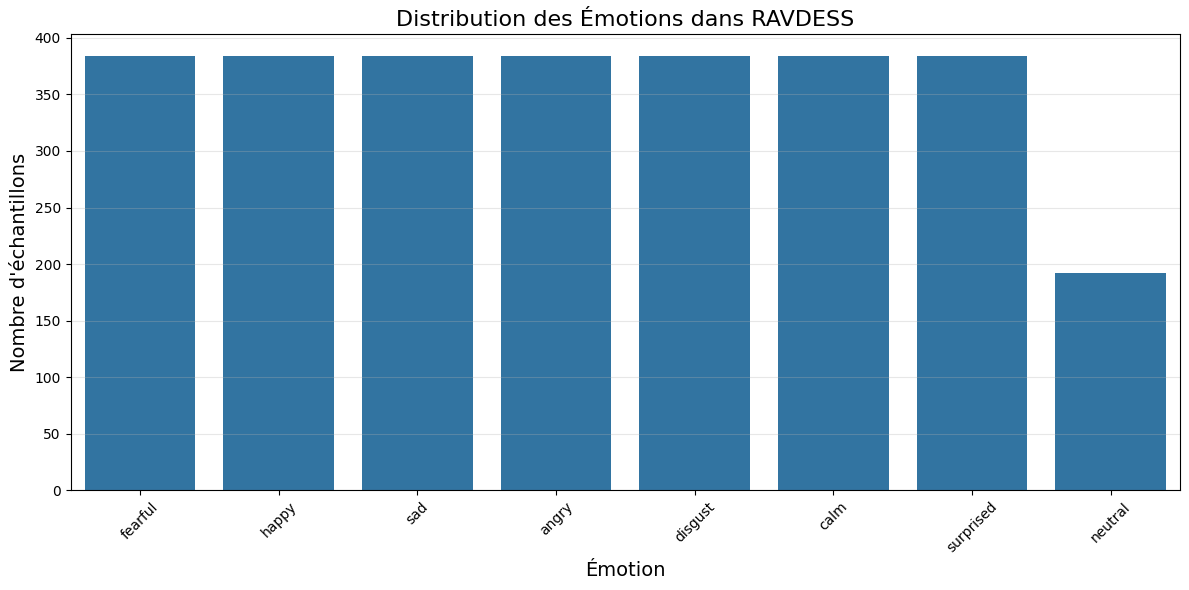

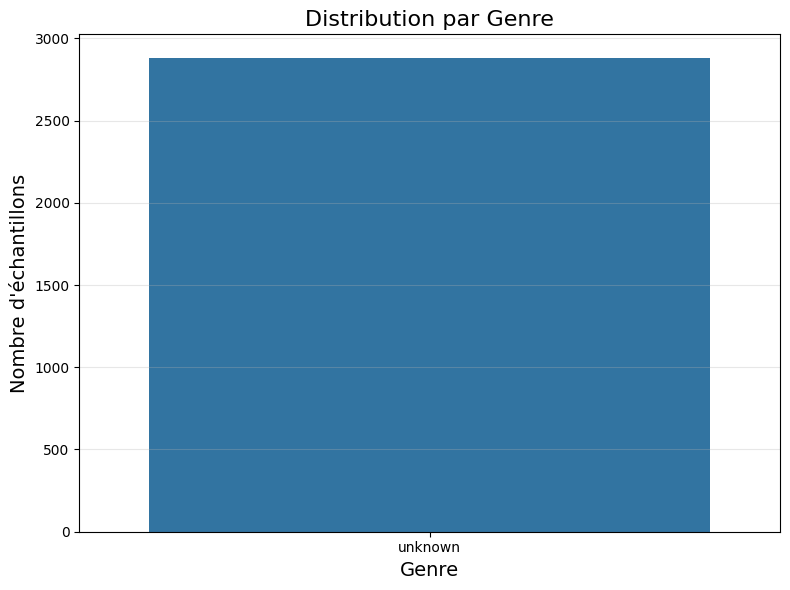

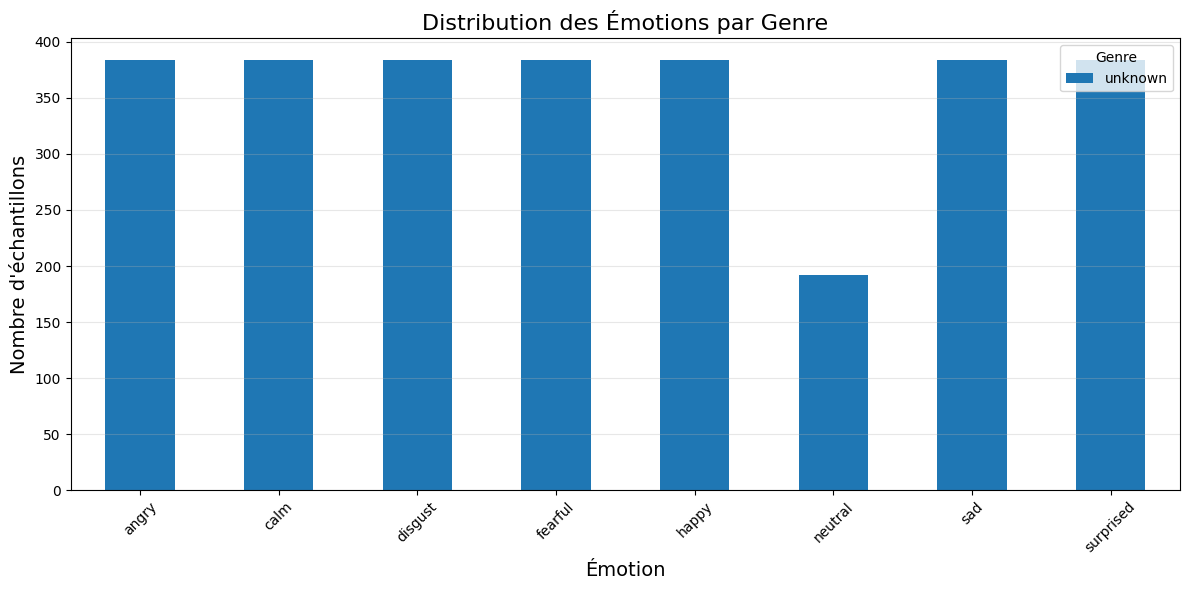

In [8]:
# Distribution des émotions
plt.figure(figsize=(12, 6))
emotion_counts = df['emotion'].value_counts()
sns.barplot(x=emotion_counts.index, y=emotion_counts.values)
plt.title('Distribution des Émotions dans RAVDESS', fontsize=16)
plt.xlabel('Émotion', fontsize=14)
plt.ylabel("Nombre d'échantillons", fontsize=14)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Distribution par genre
plt.figure(figsize=(8, 6))
gender_counts = df['gender'].value_counts()
sns.barplot(x=gender_counts.index, y=gender_counts.values)
plt.title('Distribution par Genre', fontsize=16)
plt.xlabel('Genre', fontsize=14)
plt.ylabel("Nombre d'échantillons", fontsize=14)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Émotion vs Genre
emotion_gender = pd.crosstab(df['emotion'], df['gender'])
emotion_gender.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Distribution des Émotions par Genre', fontsize=16)
plt.xlabel('Émotion', fontsize=14)
plt.ylabel("Nombre d'échantillons", fontsize=14)
plt.xticks(rotation=45)
plt.legend(title='Genre')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

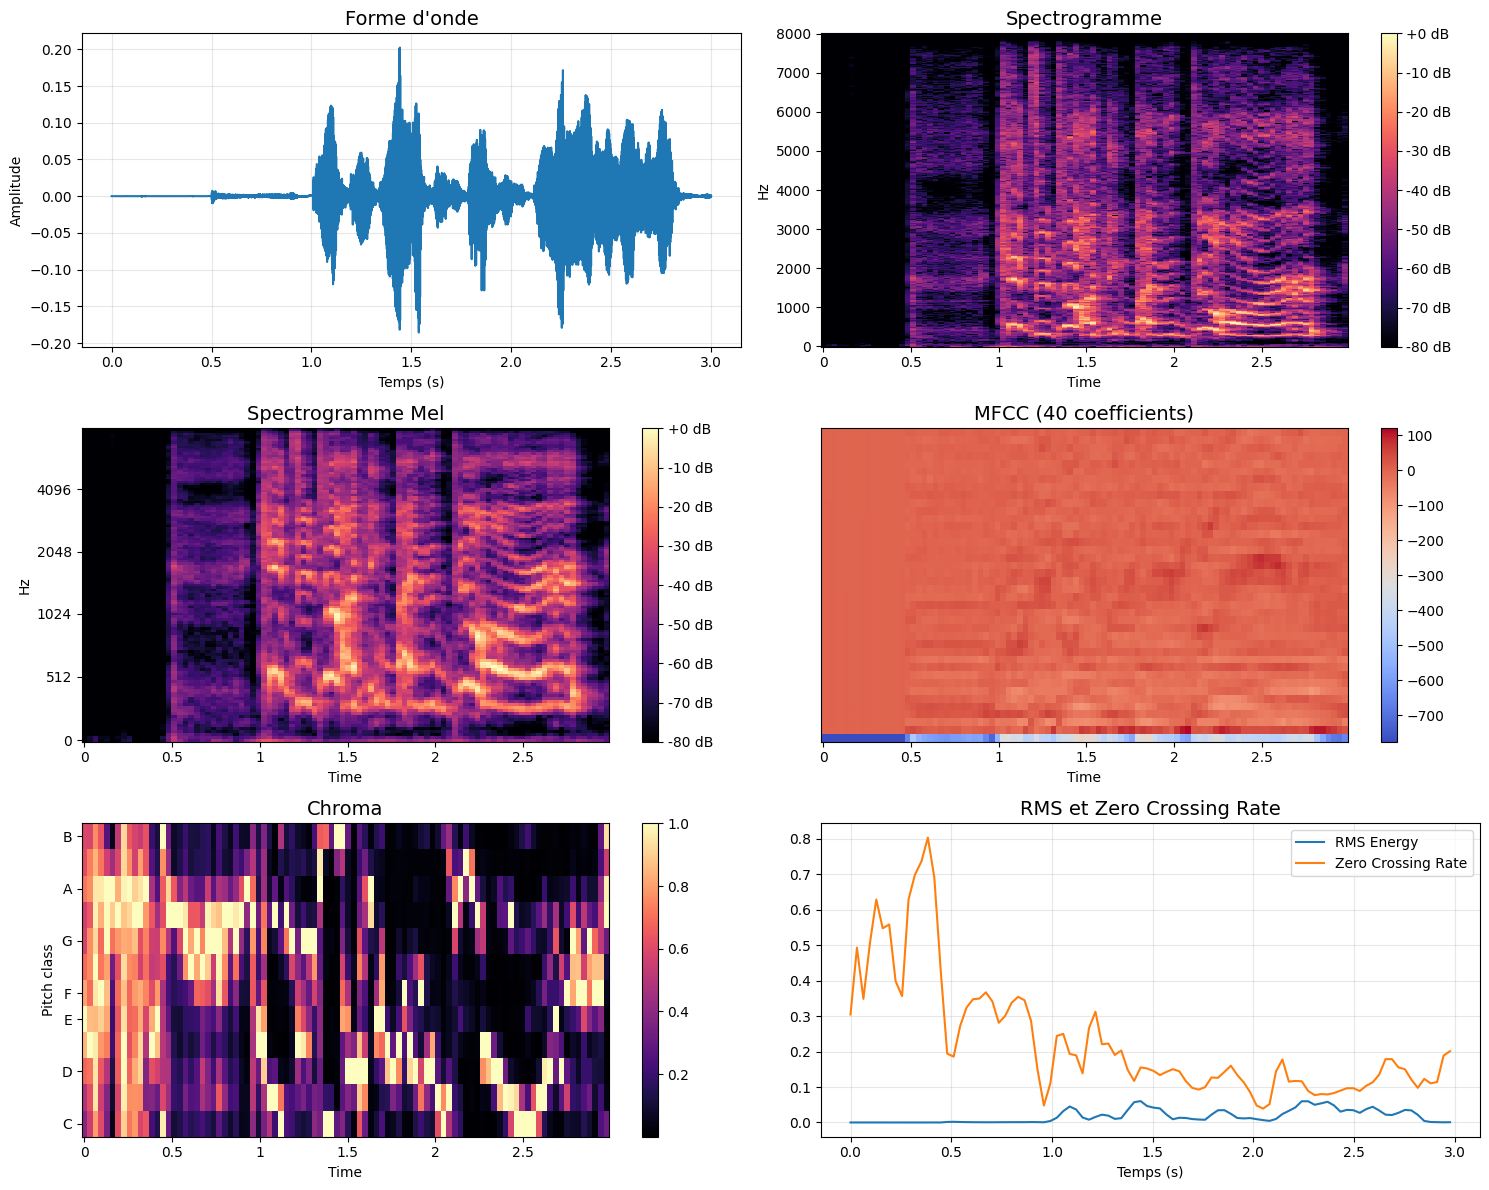

📊 Fichier: 03-01-06-02-01-01-19.wav
🎯 Émotion: fearful


In [9]:
def visualize_audio(file_path):
    """Visualiser un fichier audio : forme d'onde, spectrogramme, Mel, MFCC, chroma, RMS/ZCR"""
    audio, sr = librosa.load(file_path, sr=SAMPLE_RATE, duration=DURATION)

    fig, axes = plt.subplots(3, 2, figsize=(15, 12))

    # 1. Forme d'onde
    time = np.linspace(0, len(audio)/sr, len(audio))
    axes[0, 0].plot(time, audio)
    axes[0, 0].set_title("Forme d'onde", fontsize=14)
    axes[0, 0].set_xlabel('Temps (s)')
    axes[0, 0].set_ylabel('Amplitude')
    axes[0, 0].grid(True, alpha=0.3)

    # 2. Spectrogramme
    D = librosa.stft(audio, n_fft=N_FFT, hop_length=HOP_LENGTH)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    img = librosa.display.specshow(S_db, sr=sr, hop_length=HOP_LENGTH,
                                   x_axis='time', y_axis='hz', ax=axes[0, 1])
    axes[0, 1].set_title('Spectrogramme', fontsize=14)
    plt.colorbar(img, ax=axes[0, 1], format='%+2.0f dB')

    # 3. Spectrogramme Mel
    mel_spec = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=N_MELS,
                                              n_fft=N_FFT, hop_length=HOP_LENGTH)
    mel_db = librosa.power_to_db(mel_spec, ref=np.max)
    img = librosa.display.specshow(mel_db, sr=sr, hop_length=HOP_LENGTH,
                                   x_axis='time', y_axis='mel', ax=axes[1, 0])
    axes[1, 0].set_title('Spectrogramme Mel', fontsize=14)
    plt.colorbar(img, ax=axes[1, 0], format='%+2.0f dB')

    # 4. MFCC
    mfccs = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=N_MFCC,
                                 n_fft=N_FFT, hop_length=HOP_LENGTH)
    img = librosa.display.specshow(mfccs, sr=sr, hop_length=HOP_LENGTH,
                                   x_axis='time', ax=axes[1, 1])
    axes[1, 1].set_title(f'MFCC ({N_MFCC} coefficients)', fontsize=14)
    plt.colorbar(img, ax=axes[1, 1])

    # 5. Chroma
    chroma = librosa.feature.chroma_stft(y=audio, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)
    img = librosa.display.specshow(chroma, sr=sr, hop_length=HOP_LENGTH,
                                   x_axis='time', y_axis='chroma', ax=axes[2, 0])
    axes[2, 0].set_title('Chroma', fontsize=14)
    plt.colorbar(img, ax=axes[2, 0])

    # 6. RMS et Zero Crossing Rate
    rms = librosa.feature.rms(y=audio, frame_length=N_FFT, hop_length=HOP_LENGTH)
    zcr = librosa.feature.zero_crossing_rate(audio, frame_length=N_FFT, hop_length=HOP_LENGTH)

    frames = np.arange(len(rms[0]))
    time_frames = librosa.frames_to_time(frames, sr=sr, hop_length=HOP_LENGTH)
    axes[2, 1].plot(time_frames, rms[0], label='RMS Energy')
    axes[2, 1].plot(time_frames, zcr[0], label='Zero Crossing Rate')
    axes[2, 1].set_title('RMS et Zero Crossing Rate', fontsize=14)
    axes[2, 1].set_xlabel('Temps (s)')
    axes[2, 1].legend()
    axes[2, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    filename = os.path.basename(file_path)
    emotion = extract_emotion_from_filename(filename)
    print(f"📊 Fichier: {filename}")
    print(f"🎯 Émotion: {emotion}")

# Visualiser un exemple
if len(data) > 0:
    visualize_audio(data[0]['file_path'])
else:
    print("❌ Aucun fichier audio trouvé !")

## 6. Fonctions d'extraction de caractéristiques audio

Ces fonctions sont utilisées par les modèles **CNN** (spectrogramme Mel 2D) et **LSTM** (séquence MFCC).

In [10]:
def extract_features(file_path, duration=DURATION, sr=SAMPLE_RATE):
    """Extraire un ensemble complet de caractéristiques d'un fichier audio (pour le CNN)"""
    try:
        audio, sr = librosa.load(file_path, sr=sr, duration=duration)

        if len(audio) < sr * duration:
            audio = np.pad(audio, (0, sr * duration - len(audio)))
        else:
            audio = audio[:sr * duration]

        mel_spec = librosa.feature.melspectrogram(
            y=audio, sr=sr, n_mels=N_MELS, n_fft=N_FFT, hop_length=HOP_LENGTH
        )
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

        mfccs = librosa.feature.mfcc(
            y=audio, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH
        )

        chroma = librosa.feature.chroma_stft(
            y=audio, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH
        )

        rms = librosa.feature.rms(y=audio, frame_length=N_FFT, hop_length=HOP_LENGTH)
        zcr = librosa.feature.zero_crossing_rate(audio, frame_length=N_FFT, hop_length=HOP_LENGTH)

        mfcc_mean = np.mean(mfccs, axis=1)
        mfcc_std = np.std(mfccs, axis=1)

        return {
            'mel_spec': mel_spec_db,
            'mfcc': mfccs,
            'chroma': chroma,
            'rms': rms,
            'zcr': zcr,
            'mfcc_mean': mfcc_mean,
            'mfcc_std': mfcc_std,
            'audio': audio
        }

    except Exception as e:
        print(f"Erreur avec {file_path}: {e}")
        return None


def prepare_data_for_cnn(data, target_size=(128, 128)):
    """Préparer les spectrogrammes Mel redimensionnés pour le CNN"""
    X, y, valid_indices = [], [], []

    for idx, item in enumerate(tqdm(data, desc="Extraction des caractéristiques (CNN)")):
        features = extract_features(item['file_path'])
        if features is not None:
            mel_spec = features['mel_spec']
            mel_spec_resized = tf.image.resize(
                mel_spec[..., np.newaxis], target_size
            ).numpy().squeeze()

            X.append(mel_spec_resized)
            y.append(item['emotion'])
            valid_indices.append(idx)

    return np.array(X), np.array(y), valid_indices


def extract_mfcc_sequence(file_path, duration=DURATION, sr=SAMPLE_RATE, n_mfcc=N_MFCC):
    """Extraire les MFCC séquentiels (pour le LSTM)"""
    try:
        audio, sr = librosa.load(file_path, sr=sr, duration=duration)

        if len(audio) < sr * duration:
            audio = np.pad(audio, (0, sr * duration - len(audio)))
        else:
            audio = audio[:sr * duration]

        mfccs = librosa.feature.mfcc(
            y=audio, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
        )
        return mfccs.T  # (time_steps, n_mfcc)

    except Exception as e:
        print(f"Erreur: {e}")
        return None


def prepare_data_for_lstm(data, max_sequence_length=None):
    """Préparer les séquences MFCC paddées pour le LSTM"""
    X, y, valid_indices, sequence_lengths = [], [], [], []

    for idx, item in enumerate(tqdm(data, desc="Extraction des séquences MFCC (LSTM)")):
        mfcc_seq = extract_mfcc_sequence(item['file_path'])
        if mfcc_seq is not None:
            sequence_lengths.append(len(mfcc_seq))
            X.append(mfcc_seq)
            y.append(item['emotion'])
            valid_indices.append(idx)

    if max_sequence_length is None:
        max_sequence_length = int(np.percentile(sequence_lengths, 95))

    print(f"📊 Longueur maximale de séquence: {max_sequence_length}")

    X_padded = []
    for seq in X:
        if len(seq) < max_sequence_length:
            pad_length = max_sequence_length - len(seq)
            seq_padded = np.pad(seq, ((0, pad_length), (0, 0)), mode='constant')
        else:
            seq_padded = seq[:max_sequence_length]
        X_padded.append(seq_padded)

    return np.array(X_padded), np.array(y), valid_indices, max_sequence_length


print("✅ Fonctions d'extraction prêtes (CNN + LSTM) !")

✅ Fonctions d'extraction prêtes (CNN + LSTM) !


---
# 🅰️ Partie A — Modèle CNN 2D

Classification à partir des **spectrogrammes Mel** (image 2D), via un CNN convolutif.

### A.1 Préparation des données

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models

print("🔧 Préparation des données pour le CNN...")
X, y, valid_indices = prepare_data_for_cnn(data)

print(f"\n📊 Forme des données :")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(label_encoder.classes_)

print(f"\n🎯 Classes : {label_encoder.classes_}")
print(f"Nombre de classes : {num_classes}")

print("\n📊 Distribution des classes :")
unique, counts = np.unique(y, return_counts=True)
for emotion, count in zip(unique, counts):
    print(f"  {emotion}: {count}")

# Split en train/validation/test (70/15/15)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"\n📊 Split des données :")
print(f"  Train: {len(X_train)} échantillons")
print(f"  Validation: {len(X_val)} échantillons")
print(f"  Test: {len(X_test)} échantillons")

# Ajouter la dimension canal pour CNN
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print(f"\n✅ Forme finale des données :")
print(f"  X_train: {X_train.shape}")
print(f"  X_val: {X_val.shape}")
print(f"  X_test: {X_test.shape}")

🔧 Préparation des données pour le CNN...


Extraction des caractéristiques (CNN): 100%|██████████| 2880/2880 [01:05<00:00, 43.99it/s]



📊 Forme des données :
X shape: (2880, 128, 128)
y shape: (2880,)

🎯 Classes : ['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']
Nombre de classes : 8

📊 Distribution des classes :
  angry: 384
  calm: 384
  disgust: 384
  fearful: 384
  happy: 384
  neutral: 192
  sad: 384
  surprised: 384

📊 Split des données :
  Train: 2016 échantillons
  Validation: 432 échantillons
  Test: 432 échantillons

✅ Forme finale des données :
  X_train: (2016, 128, 128, 1)
  X_val: (432, 128, 128, 1)
  X_test: (432, 128, 128, 1)


### A.2 Construction du modèle

In [12]:
def build_cnn_model(input_shape=(128, 128, 1), num_classes=8):
    """Construire un modèle CNN 2D pour la SER"""
    model = models.Sequential([
        # Bloc 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Bloc 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Bloc 3
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Bloc 4
        layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Classifier
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])

    return model

cnn_model = build_cnn_model(num_classes=num_classes)
cnn_model.summary()

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ Modèle CNN construit et compilé !")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           51

 Total params: 491,016 (1.87 MB)

 Trainable params: 489,288 (1.87 MB)

 Non-trainable params: 1,728 (6.75 KB)

✅ Modèle CNN construit et compilé !


### A.3 Entraînement

In [13]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger

def train_model(model, X_train, y_train, X_val, y_val, epochs=100, batch_size=32,
                 checkpoint_path='best_cnn_model.h5', log_path='training_log.csv'):
    """Entraîner le modèle avec callbacks"""
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
        ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
        CSVLogger(log_path)
    ]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=1
    )

    return history

print("🏋️ Début de l'entraînement CNN...")
history = train_model(cnn_model, X_train, y_train, X_val, y_val)

cnn_model.load_weights('best_cnn_model.h5')
print("✅ Meilleur modèle CNN chargé !")

🏋️ Début de l'entraînement CNN...
Epoch 1/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1997 - loss: 2.9066
Epoch 1: val_accuracy improved from None to 0.13426, saving model to best_cnn_model.h5



Epoch 1: finished saving model to best_cnn_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 62ms/step - accuracy: 0.2450 - loss: 2.6271 - val_accuracy: 0.1343 - val_loss: 3.5955 - learning_rate: 0.0010
Epoch 2/100
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.3120 - loss: 2.1246
Epoch 2: val_accuracy did not improve from 0.13426
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.3204 - loss: 2.1083 - val_accuracy: 0.1319 - val_loss: 2.3502 - learning_rate: 0.0010
Epoch 3/100
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3777 - loss: 1.8769
Epoch 3: val_accuracy improved from 0.13426 to 0.19907, saving model to best_cnn_model.h5



Epoch 3: finished saving model to best_cnn_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.3641 - loss: 1.9022 - val_accuracy: 0.1991 - val_loss: 2.4259 - learning_rate: 0.0010
Epoch 4/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3759 - loss: 1.8472
Epoch 4: val_accuracy improved from 0.19907 to 0.28472, saving model to best_cnn_model.h5



Epoch 4: finished saving model to best_cnn_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.3884 - loss: 1.8103 - val_accuracy: 0.2847 - val_loss: 1.9808 - learning_rate: 0.0010
Epoch 5/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4180 - loss: 1.6112
Epoch 5: val_accuracy improved from 0.28472 to 0.30324, saving model to best_cnn_model.h5



Epoch 5: finished saving model to best_cnn_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.4311 - loss: 1.6058 - val_accuracy: 0.3032 - val_loss: 3.4090 - learning_rate: 0.0010
Epoch 6/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4607 - loss: 1.5318
Epoch 6: val_accuracy did not improve from 0.30324
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.4573 - loss: 1.5305 - val_accuracy: 0.2130 - val_loss: 4.5185 - learning_rate: 0.0010
Epoch 7/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4898 - loss: 1.4120
Epoch 7: val_accuracy did not improve from 0.30324
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.4757 - loss: 1.4359 - val_accuracy: 0.2014 - val_loss: 4.6131 - learning_rate: 0.0010
Epoch 8/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4861 - loss: 1.3843
Epoch 8: val_accuracy did not improve from 0.30324
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.4980 - loss: 1.3813 - val_accuracy: 0.1389 - val_loss: 5.5402 

...


Epoch 31: finished saving model to best_cnn_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.8690 - loss: 0.4022 - val_accuracy: 0.7523 - val_loss: 0.8075 - learning_rate: 2.5000e-04
Epoch 32/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8746 - loss: 0.3687
Epoch 32: val_accuracy did not improve from 0.75231
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.8800 - loss: 0.3660 - val_accuracy: 0.6806 - val_loss: 0.9299 - learning_rate: 2.5000e-04
Epoch 33/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8616 - loss: 0.3807
Epoch 33: val_accuracy did not improve from 0.75231
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.8507 - loss: 0.4067 - val_accuracy: 0.6806 - val_loss: 1.0742 - learning_rate: 2.5000e-04
Epoch 34/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8799 - loss: 0.3456
Epoch 34: val_accuracy did not improve from 0.75231
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.8770 - loss: 0.3550 - val_accuracy: 0.6968 


Epoch 36: finished saving model to best_cnn_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.8715 - loss: 0.3695 - val_accuracy: 0.7755 - val_loss: 0.6773 - learning_rate: 2.5000e-04
Epoch 37/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8858 - loss: 0.3604
Epoch 37: val_accuracy did not improve from 0.77546
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.8824 - loss: 0.3615 - val_accuracy: 0.7338 - val_loss: 0.8736 - learning_rate: 2.5000e-04
Epoch 38/100
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8953 - loss: 0.3098
Epoch 38: val_accuracy did not improve from 0.77546
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.8864 - loss: 0.3278 - val_accuracy: 0.6806 - val_loss: 1.1261 - learning_rate: 2.5000e-04
Epoch 39/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9017 - loss: 0.2992
Epoch 39: val_accuracy did not improve from 0.77546
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9008 - loss: 0.2997 - val_accuracy: 0.6435 


Epoch 47: finished saving model to best_cnn_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9241 - loss: 0.2298 - val_accuracy: 0.7870 - val_loss: 0.8121 - learning_rate: 6.2500e-05
Epoch 48/100
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9487 - loss: 0.1812
Epoch 48: val_accuracy did not improve from 0.78704
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.9449 - loss: 0.1880 - val_accuracy: 0.7708 - val_loss: 0.7606 - learning_rate: 6.2500e-05
Epoch 49/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9219 - loss: 0.2223
Epoch 49: val_accuracy did not improve from 0.78704
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9231 - loss: 0.2268 - val_accuracy: 0.7500 - val_loss: 0.9809 - learning_rate: 6.2500e-05
Epoch 50/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9342 - loss: 0.2007
Epoch 50: val_accuracy improved from 0.78704 to 0.83796, saving model to best_cnn_model.h5



Epoch 50: finished saving model to best_cnn_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9375 - loss: 0.2028 - val_accuracy: 0.8380 - val_loss: 0.6321 - learning_rate: 6.2500e-05
Epoch 51/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9405 - loss: 0.2027
Epoch 51: val_accuracy did not improve from 0.83796
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9444 - loss: 0.1977 - val_accuracy: 0.8287 - val_loss: 0.6450 - learning_rate: 6.2500e-05
Epoch 52/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9344 - loss: 0.2182
Epoch 52: val_accuracy did not improve from 0.83796
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9320 - loss: 0.2100 - val_accuracy: 0.8310 - val_loss: 0.5850 - learning_rate: 6.2500e-05
Epoch 53/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9411 - loss: 0.1961
Epoch 53: val_accuracy did not improve from 0.83796
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9395 - loss: 0.1975 - val_accuracy: 0.8009 


Epoch 62: finished saving model to best_cnn_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9400 - loss: 0.1783 - val_accuracy: 0.8426 - val_loss: 0.6038 - learning_rate: 3.1250e-05
Epoch 63/100
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9430 - loss: 0.1717
Epoch 63: val_accuracy did not improve from 0.84259
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9365 - loss: 0.1869 - val_accuracy: 0.8218 - val_loss: 0.6572 - learning_rate: 1.5625e-05
Epoch 64/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9548 - loss: 0.1618
Epoch 64: val_accuracy did not improve from 0.84259
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9559 - loss: 0.1589 - val_accuracy: 0.8194 - val_loss: 0.7019 - learning_rate: 1.5625e-05
Epoch 65/100
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9326 - loss: 0.2077
Epoch 65: val_accuracy did not improve from 0.84259
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9365 - loss: 0.1893 - val_accuracy: 0.8148 

### A.4 Courbes d'apprentissage

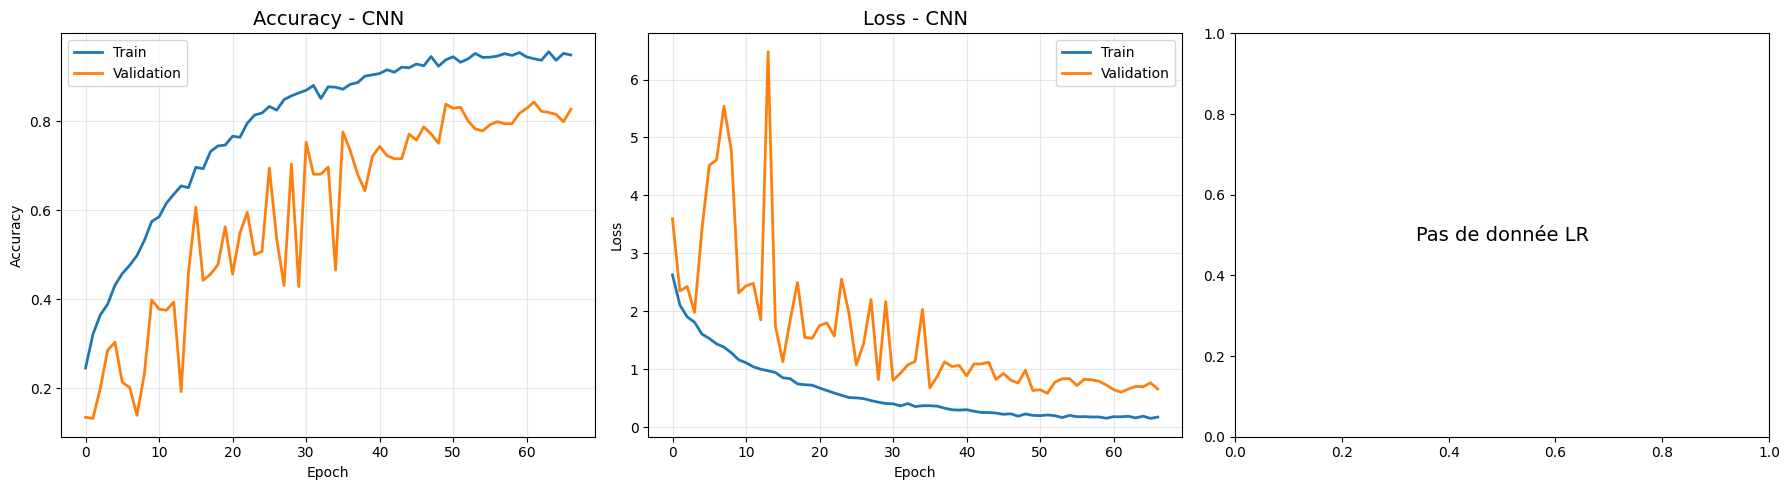


📊 Résumé des performances :
  Meilleure accuracy d'entraînement: 95.59%
  Meilleure accuracy de validation: 84.26%
  Dernière accuracy de validation: 82.64%


In [14]:
def plot_training_history(history, title_suffix=''):
    """Visualiser les courbes d'apprentissage"""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].plot(history.history['accuracy'], label='Train', linewidth=2)
    axes[0].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
    axes[0].set_title(f'Accuracy {title_suffix}', fontsize=14)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history['loss'], label='Train', linewidth=2)
    axes[1].plot(history.history['val_loss'], label='Validation', linewidth=2)
    axes[1].set_title(f'Loss {title_suffix}', fontsize=14)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    if 'lr' in history.history:
        axes[2].plot(history.history['lr'], linewidth=2)
        axes[2].set_title(f'Learning Rate {title_suffix}', fontsize=14)
        axes[2].set_xlabel('Epoch')
        axes[2].set_ylabel('Learning Rate')
        axes[2].grid(True, alpha=0.3)
    else:
        axes[2].text(0.5, 0.5, 'Pas de donnée LR', ha='center', va='center', fontsize=14)

    plt.tight_layout()
    plt.show()

plot_training_history(history, title_suffix='- CNN')

print("\n📊 Résumé des performances :")
print(f"  Meilleure accuracy d'entraînement: {max(history.history['accuracy'])*100:.2f}%")
print(f"  Meilleure accuracy de validation: {max(history.history['val_accuracy'])*100:.2f}%")
print(f"  Dernière accuracy de validation: {history.history['val_accuracy'][-1]*100:.2f}%")

### A.5 Évaluation et matrice de confusion

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step
🎯 Accuracy sur le test: 82.87%


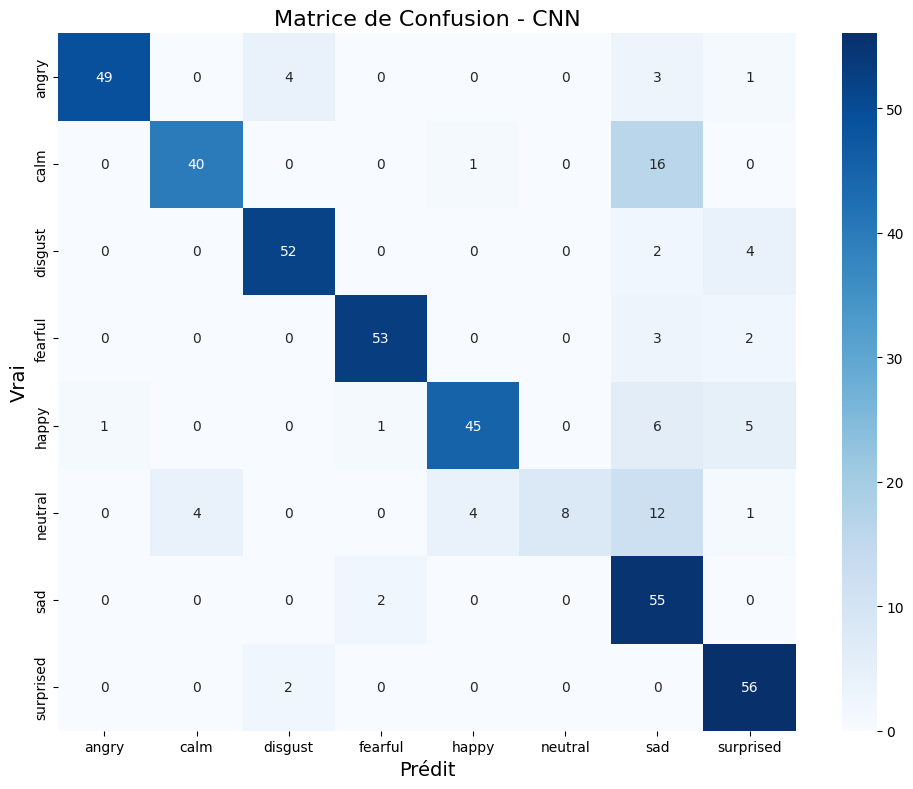


📊 Rapport de Classification - CNN:
------------------------------------------------------------
              precision    recall  f1-score   support

       angry       0.98      0.86      0.92        57
        calm       0.91      0.70      0.79        57
     disgust       0.90      0.90      0.90        58
     fearful       0.95      0.91      0.93        58
       happy       0.90      0.78      0.83        58
     neutral       1.00      0.28      0.43        29
         sad       0.57      0.96      0.71        57
   surprised       0.81      0.97      0.88        58

    accuracy                           0.83       432
   macro avg       0.88      0.79      0.80       432
weighted avg       0.87      0.83      0.82       432

✅ Résultats sauvegardés dans 'cnn_results.json'


In [15]:
def evaluate_model(model, X_test, y_test, label_encoder, title_suffix=''):
    """Évaluer le modèle et afficher les métriques"""
    y_pred_proba = model.predict(X_test)
    y_pred = np.argmax(y_pred_proba, axis=1)

    accuracy = accuracy_score(y_test, y_pred)
    print(f"🎯 Accuracy sur le test: {accuracy*100:.2f}%")

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.title(f'Matrice de Confusion {title_suffix}', fontsize=16)
    plt.xlabel('Prédit', fontsize=14)
    plt.ylabel('Vrai', fontsize=14)
    plt.tight_layout()
    plt.show()

    print(f"\n📊 Rapport de Classification {title_suffix}:")
    print("-" * 60)
    print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

    return y_pred, accuracy

y_pred, cnn_test_accuracy = evaluate_model(cnn_model, X_test, y_test, label_encoder, title_suffix='- CNN')

import json
cnn_results = {
    'model': 'CNN',
    'accuracy': cnn_test_accuracy,
    'num_classes': num_classes,
    'classes': list(label_encoder.classes_)
}
with open('cnn_results.json', 'w') as f:
    json.dump(cnn_results, f)

print("✅ Résultats sauvegardés dans 'cnn_results.json'")

### A.6 Prédiction sur un exemple

In [16]:
def predict_emotion_cnn(file_path, model, label_encoder):
    """Prédire l'émotion à partir d'un fichier audio (CNN)"""
    features = extract_features(file_path)
    if features is None:
        return "❌ Erreur: Impossible de charger l'audio", 0, []

    mel_spec = features['mel_spec']
    mel_spec_resized = tf.image.resize(mel_spec[..., np.newaxis], (128, 128)).numpy()
    mel_spec_resized = np.expand_dims(mel_spec_resized, axis=0)

    predictions = model.predict(mel_spec_resized, verbose=0)
    emotion_idx = np.argmax(predictions[0])
    emotion = label_encoder.classes_[emotion_idx]
    confidence = predictions[0][emotion_idx] * 100

    results = [(name, score * 100) for name, score in zip(label_encoder.classes_, predictions[0])]

    return emotion, confidence, results

# Tester sur un exemple du dataset
sample_file = data[valid_indices[0]]['file_path']
print(f"📂 Fichier test: {os.path.basename(sample_file)}")
print(f"🎯 Émotion réelle: {data[valid_indices[0]]['emotion']}")

emotion_pred, confidence, all_scores = predict_emotion_cnn(sample_file, cnn_model, label_encoder)
print(f"\n🔮 Prédiction: {emotion_pred} (Confiance: {confidence:.2f}%)")

print("\n📊 Scores pour toutes les émotions:")
print("-" * 40)
for emotion, score in sorted(all_scores, key=lambda x: -x[1]):
    bar = "█" * int(score / 5)
    print(f"{emotion:12} : {score:6.2f}% {bar}")

📂 Fichier test: 03-01-06-02-01-01-19.wav
🎯 Émotion réelle: fearful

🔮 Prédiction: fearful (Confiance: 99.99%)

📊 Scores pour toutes les émotions:
----------------------------------------
fearful      :  99.99% ███████████████████
sad          :   0.01% 
happy        :   0.00% 
surprised    :   0.00% 
angry        :   0.00% 
calm         :   0.00% 
disgust      :   0.00% 
neutral      :   0.00% 


### A.7 Sauvegarde du modèle CNN

In [17]:
import pickle
from datetime import datetime

cnn_model.save('cnn_ser_model.h5')
print("✅ Modèle sauvegardé: cnn_ser_model.h5")

with open('label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)
print("✅ Label encoder sauvegardé: label_encoder.pkl")

cnn_metadata = {
    'model_type': 'CNN_2D',
    'num_classes': num_classes,
    'classes': list(label_encoder.classes_),
    'input_shape': (128, 128, 1),
    'test_accuracy': cnn_test_accuracy,
    'sample_rate': SAMPLE_RATE,
    'duration': DURATION,
    'n_mels': N_MELS,
    'n_mfcc': N_MFCC,
    'training_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'dataset': 'RAVDESS',
    'num_samples': len(data),
    'train_samples': len(X_train),
    'val_samples': len(X_val),
    'test_samples': len(X_test)
}
with open('cnn_metadata.json', 'w') as f:
    json.dump(cnn_metadata, f, indent=2)
print("✅ Métadonnées sauvegardées: cnn_metadata.json")

cnn_history_dict = {
    'accuracy': history.history['accuracy'],
    'val_accuracy': history.history['val_accuracy'],
    'loss': history.history['loss'],
    'val_loss': history.history['val_loss']
}
with open('training_history.json', 'w') as f:
    json.dump(cnn_history_dict, f)
print("✅ Historique d'entraînement sauvegardé: training_history.json")

print("\n" + "="*50)
print("🎤 PARTIE A - RÉSUMÉ CNN")
print("="*50)
print(f"📊 Dataset: RAVDESS")
print(f"🎯 Classes: {list(label_encoder.classes_)}")
print(f"📈 Accuracy sur le test: {cnn_test_accuracy*100:.2f}%")
print("="*50)

✅ Modèle sauvegardé: cnn_ser_model.h5
✅ Label encoder sauvegardé: label_encoder.pkl
✅ Métadonnées sauvegardées: cnn_metadata.json
✅ Historique d'entraînement sauvegardé: training_history.json

🎤 PARTIE A - RÉSUMÉ CNN
📊 Dataset: RAVDESS
🎯 Classes: [np.str_('angry'), np.str_('calm'), np.str_('disgust'), np.str_('fearful'), np.str_('happy'), np.str_('neutral'), np.str_('sad'), np.str_('surprised')]
📈 Accuracy sur le test: 82.87%


---
# 🅱️ Partie B — Modèle LSTM

Classification à partir de **séquences temporelles de MFCC**, via un réseau LSTM empilé.

### B.1 Préparation des données

In [18]:
print("🔧 Préparation des données LSTM...")
X_lstm, y_lstm, valid_indices_lstm, max_seq_len = prepare_data_for_lstm(data)

print(f"\n📊 Forme des données LSTM:")
print(f"  X shape: {X_lstm.shape}")
print(f"  y shape: {y_lstm.shape}")

label_encoder_lstm = LabelEncoder()
y_encoded_lstm = label_encoder_lstm.fit_transform(y_lstm)
num_classes_lstm = len(label_encoder_lstm.classes_)

print(f"\n🎯 Classes: {label_encoder_lstm.classes_}")
print(f"Nombre de classes: {num_classes_lstm}")

# Split en train/validation/test
X_train_lstm, X_temp_lstm, y_train_lstm, y_temp_lstm = train_test_split(
    X_lstm, y_encoded_lstm, test_size=0.3, random_state=42, stratify=y_encoded_lstm
)
X_val_lstm, X_test_lstm, y_val_lstm, y_test_lstm = train_test_split(
    X_temp_lstm, y_temp_lstm, test_size=0.5, random_state=42, stratify=y_temp_lstm
)

print(f"\n📊 Split des données LSTM:")
print(f"  Train: {len(X_train_lstm)} échantillons")
print(f"  Validation: {len(X_val_lstm)} échantillons")
print(f"  Test: {len(X_test_lstm)} échantillons")
print(f"  Séquence length: {X_train_lstm.shape[1]}")
print(f"  Features (MFCC): {X_train_lstm.shape[2]}")

🔧 Préparation des données LSTM...


Extraction des séquences MFCC (LSTM): 100%|██████████| 2880/2880 [00:26<00:00, 108.09it/s]


📊 Longueur maximale de séquence: 94

📊 Forme des données LSTM:
  X shape: (2880, 94, 40)
  y shape: (2880,)

🎯 Classes: ['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']
Nombre de classes: 8

📊 Split des données LSTM:
  Train: 2016 échantillons
  Validation: 432 échantillons
  Test: 432 échantillons
  Séquence length: 94
  Features (MFCC): 40


### B.2 Construction du modèle

In [19]:
def build_lstm_model(input_shape, num_classes=8):
    """Construire un modèle LSTM pour la SER"""
    model = models.Sequential([
        layers.LSTM(128, return_sequences=True, input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.LSTM(64, return_sequences=True),
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.LSTM(32, return_sequences=False),
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),

        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),

        layers.Dense(num_classes, activation='softmax')
    ])

    return model

input_shape_lstm = (X_train_lstm.shape[1], X_train_lstm.shape[2])
lstm_model = build_lstm_model(input_shape_lstm, num_classes_lstm)
lstm_model.summary()

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ Modèle LSTM construit et compilé !")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 94, 128)        │        86,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 94, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 94, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 94, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 94, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 94, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 154,088 (601.91 KB)

 Trainable params: 153,448 (599.41 KB)

 Non-trainable params: 640 (2.50 KB)

✅ Modèle LSTM construit et compilé !


### B.3 Entraînement

In [20]:
print("🏋️ Début de l'entraînement LSTM...")
print("⚠️ Cela peut prendre du temps...")
history_lstm = train_model(lstm_model, X_train_lstm, y_train_lstm, X_val_lstm, y_val_lstm,
                            checkpoint_path='best_lstm_model.h5', log_path='training_log_lstm.csv')

lstm_model.load_weights('best_lstm_model.h5')
print("✅ Meilleur modèle LSTM chargé !")

🏋️ Début de l'entraînement LSTM...
⚠️ Cela peut prendre du temps...
Epoch 1/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1469 - loss: 2.6837
Epoch 1: val_accuracy improved from None to 0.25000, saving model to best_lstm_model.h5



Epoch 1: finished saving model to best_lstm_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.1815 - loss: 2.5088 - val_accuracy: 0.2500 - val_loss: 2.0348 - learning_rate: 0.0010
Epoch 2/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2171 - loss: 2.3080
Epoch 2: val_accuracy did not improve from 0.25000
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.2267 - loss: 2.2297 - val_accuracy: 0.2500 - val_loss: 1.9304 - learning_rate: 0.0010
Epoch 3/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2682 - loss: 2.0238
Epoch 3: val_accuracy did not improve from 0.25000
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.2847 - loss: 1.9942 - val_accuracy: 0.2384 - val_loss: 2.0197 - learning_rate: 0.0010
Epoch 4/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3115 - loss: 1.9072
Epoch 4: val_accuracy improved from 0.25000 to 0.28704, saving model to best_lstm_model.h5



Epoch 4: finished saving model to best_lstm_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.3204 - loss: 1.8824 - val_accuracy: 0.2870 - val_loss: 1.9201 - learning_rate: 0.0010
Epoch 5/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3264 - loss: 1.7625
Epoch 5: val_accuracy improved from 0.28704 to 0.38889, saving model to best_lstm_model.h5



Epoch 5: finished saving model to best_lstm_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.3249 - loss: 1.7906 - val_accuracy: 0.3889 - val_loss: 1.6470 - learning_rate: 0.0010
Epoch 6/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3463 - loss: 1.7694
Epoch 6: val_accuracy did not improve from 0.38889
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.3428 - loss: 1.7602 - val_accuracy: 0.3889 - val_loss: 1.7122 - learning_rate: 0.0010
Epoch 7/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3777 - loss: 1.6851
Epoch 7: val_accuracy improved from 0.38889 to 0.45833, saving model to best_lstm_model.h5



Epoch 7: finished saving model to best_lstm_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.3750 - loss: 1.6772 - val_accuracy: 0.4583 - val_loss: 1.5686 - learning_rate: 0.0010
Epoch 8/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4175 - loss: 1.6160
Epoch 8: val_accuracy did not improve from 0.45833
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.3983 - loss: 1.6392 - val_accuracy: 0.4005 - val_loss: 1.6779 - learning_rate: 0.0010
Epoch 9/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4319 - loss: 1.5738
Epoch 9: val_accuracy did not improve from 0.45833
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.4172 - loss: 1.5973 - val_accuracy: 0.4259 - val_loss: 1.4969 - learning_rate: 0.0010
Epoch 10/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4205 - loss: 1.5648
Epoch 10: val_accuracy improved from 0.45833 to 0.46528, saving model to best_lstm_model.h5


...


Epoch 68: finished saving model to best_lstm_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9355 - loss: 0.2607 - val_accuracy: 0.9005 - val_loss: 0.4175 - learning_rate: 1.2500e-04
Epoch 69/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9211 - loss: 0.3007
Epoch 69: val_accuracy did not improve from 0.90046
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.9226 - loss: 0.2912 - val_accuracy: 0.8981 - val_loss: 0.4324 - learning_rate: 1.2500e-04
Epoch 70/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9280 - loss: 0.2929
Epoch 70: val_accuracy did not improve from 0.90046
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9266 - loss: 0.2838 - val_accuracy: 0.8843 - val_loss: 0.4607 - learning_rate: 1.2500e-04
Epoch 71/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9369 - loss: 0.2513
Epoch 71: val_accuracy did not improve from 0.90046
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9311 - loss: 0.2691 - val_accuracy: 0.8981


Epoch 81: finished saving model to best_lstm_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9454 - loss: 0.2287 - val_accuracy: 0.9051 - val_loss: 0.4137 - learning_rate: 3.1250e-05
Epoch 82/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9441 - loss: 0.2417
Epoch 82: val_accuracy did not improve from 0.90509
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9400 - loss: 0.2386 - val_accuracy: 0.8981 - val_loss: 0.4297 - learning_rate: 3.1250e-05
Epoch 83/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9345 - loss: 0.2490
Epoch 83: val_accuracy did not improve from 0.90509
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9335 - loss: 0.2603 - val_accuracy: 0.8912 - val_loss: 0.4487 - learning_rate: 3.1250e-05
Epoch 84/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9353 - loss: 0.2368
Epoch 84: val_accuracy improved from 0.90509 to 0.90741, saving model to best_lstm_model.h5



Epoch 84: finished saving model to best_lstm_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9390 - loss: 0.2328 - val_accuracy: 0.9074 - val_loss: 0.4261 - learning_rate: 3.1250e-05
Epoch 85/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9412 - loss: 0.2468
Epoch 85: val_accuracy did not improve from 0.90741
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.9420 - loss: 0.2402 - val_accuracy: 0.8912 - val_loss: 0.4514 - learning_rate: 3.1250e-05
Epoch 86/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9474 - loss: 0.2532
Epoch 86: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.

Epoch 86: val_accuracy did not improve from 0.90741
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9439 - loss: 0.2415 - val_accuracy: 0.9074 - val_loss: 0.4217 - learning_rate: 3.1250e-05
Epoch 87/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9464 - loss: 0.2397
Epoch 87: val_accuracy did not improve from 0.90741
63/63 ━━━━━━━━━━━


Epoch 88: finished saving model to best_lstm_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9410 - loss: 0.2331 - val_accuracy: 0.9097 - val_loss: 0.4138 - learning_rate: 1.5625e-05
Epoch 89/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9427 - loss: 0.2606
Epoch 89: val_accuracy improved from 0.90972 to 0.91435, saving model to best_lstm_model.h5



Epoch 89: finished saving model to best_lstm_model.h5
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9405 - loss: 0.2597 - val_accuracy: 0.9144 - val_loss: 0.4064 - learning_rate: 1.5625e-05
Epoch 90/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9532 - loss: 0.2071
Epoch 90: val_accuracy did not improve from 0.91435
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9459 - loss: 0.2263 - val_accuracy: 0.9074 - val_loss: 0.4244 - learning_rate: 1.5625e-05
Epoch 91/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9479 - loss: 0.1991
Epoch 91: val_accuracy did not improve from 0.91435
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9454 - loss: 0.2113 - val_accuracy: 0.9051 - val_loss: 0.4169 - learning_rate: 1.5625e-05
Epoch 92/100
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9506 - loss: 0.2017
Epoch 92: val_accuracy did not improve from 0.91435
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9474 - loss: 0.2213 - val_accuracy: 0.9051

### B.4 Courbes d'apprentissage

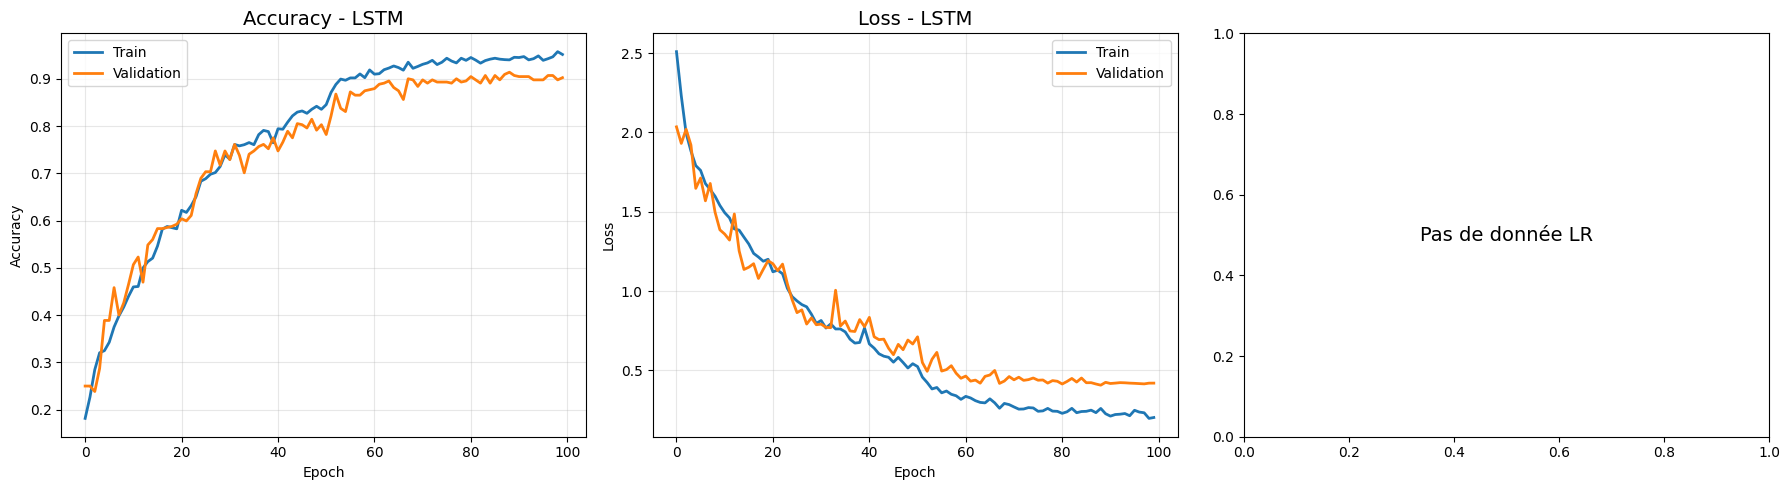


📊 Résumé des performances LSTM:
  Meilleure accuracy d'entraînement: 95.78%
  Meilleure accuracy de validation: 91.44%


In [21]:
plot_training_history(history_lstm, title_suffix='- LSTM')

print("\n📊 Résumé des performances LSTM:")
print(f"  Meilleure accuracy d'entraînement: {max(history_lstm.history['accuracy'])*100:.2f}%")
print(f"  Meilleure accuracy de validation: {max(history_lstm.history['val_accuracy'])*100:.2f}%")

### B.5 Évaluation et matrice de confusion

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step
🎯 Accuracy sur le test: 87.04%


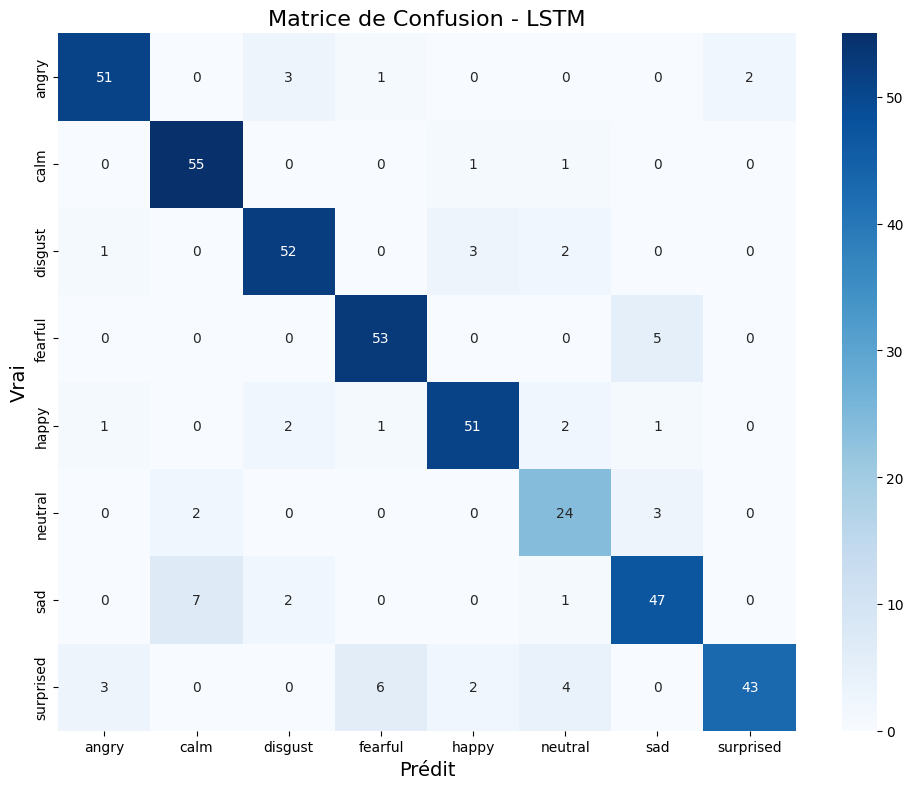


📊 Rapport de Classification - LSTM:
------------------------------------------------------------
              precision    recall  f1-score   support

       angry       0.91      0.89      0.90        57
        calm       0.86      0.96      0.91        57
     disgust       0.88      0.90      0.89        58
     fearful       0.87      0.91      0.89        58
       happy       0.89      0.88      0.89        58
     neutral       0.71      0.83      0.76        29
         sad       0.84      0.82      0.83        57
   surprised       0.96      0.74      0.83        58

    accuracy                           0.87       432
   macro avg       0.86      0.87      0.86       432
weighted avg       0.88      0.87      0.87       432

✅ Résultats LSTM sauvegardés dans 'lstm_results.json'


In [22]:
y_pred_lstm, lstm_test_accuracy = evaluate_model(lstm_model, X_test_lstm, y_test_lstm,
                                                  label_encoder_lstm, title_suffix='- LSTM')

lstm_results = {
    'model': 'LSTM',
    'accuracy': lstm_test_accuracy,
    'num_classes': num_classes_lstm,
    'classes': list(label_encoder_lstm.classes_),
    'sequence_length': int(X_train_lstm.shape[1]),
    'n_mfcc': N_MFCC
}
with open('lstm_results.json', 'w') as f:
    json.dump(lstm_results, f)

print("✅ Résultats LSTM sauvegardés dans 'lstm_results.json'")

### B.6 Prédiction sur un exemple

In [23]:
def predict_emotion_lstm(file_path, model, label_encoder, max_seq_len):
    """Prédire l'émotion avec le modèle LSTM"""
    mfcc_seq = extract_mfcc_sequence(file_path)
    if mfcc_seq is None:
        return "❌ Erreur: Impossible de charger l'audio", 0, []

    if len(mfcc_seq) < max_seq_len:
        pad_length = max_seq_len - len(mfcc_seq)
        mfcc_seq_padded = np.pad(mfcc_seq, ((0, pad_length), (0, 0)), mode='constant')
    else:
        mfcc_seq_padded = mfcc_seq[:max_seq_len]

    mfcc_seq_padded = np.expand_dims(mfcc_seq_padded, axis=0)

    predictions = model.predict(mfcc_seq_padded, verbose=0)
    emotion_idx = np.argmax(predictions[0])
    emotion = label_encoder.classes_[emotion_idx]
    confidence = predictions[0][emotion_idx] * 100

    results = [(name, score * 100) for name, score in zip(label_encoder.classes_, predictions[0])]

    return emotion, confidence, results

sample_file = data[valid_indices_lstm[0]]['file_path']
print(f"📂 Fichier test: {os.path.basename(sample_file)}")
print(f"🎯 Émotion réelle: {data[valid_indices_lstm[0]]['emotion']}")

emotion_pred, confidence, all_scores = predict_emotion_lstm(
    sample_file, lstm_model, label_encoder_lstm, max_seq_len
)
print(f"\n🔮 Prédiction LSTM: {emotion_pred} (Confiance: {confidence:.2f}%)")

print("\n📊 Scores LSTM par émotion:")
print("-" * 40)
for emotion, score in sorted(all_scores, key=lambda x: -x[1]):
    bar = "█" * int(score / 5)
    print(f"{emotion:12} : {score:6.2f}% {bar}")

📂 Fichier test: 03-01-06-02-01-01-19.wav
🎯 Émotion réelle: fearful

🔮 Prédiction LSTM: fearful (Confiance: 99.73%)

📊 Scores LSTM par émotion:
----------------------------------------
fearful      :  99.73% ███████████████████
happy        :   0.12% 
sad          :   0.08% 
surprised    :   0.05% 
angry        :   0.01% 
calm         :   0.00% 
neutral      :   0.00% 
disgust      :   0.00% 


### B.7 Sauvegarde du modèle LSTM

In [24]:
lstm_model.save('lstm_ser_model.h5')
print("✅ Modèle LSTM sauvegardé: lstm_ser_model.h5")

with open('label_encoder_lstm.pkl', 'wb') as f:
    pickle.dump(label_encoder_lstm, f)
print("✅ Label encoder LSTM sauvegardé: label_encoder_lstm.pkl")

lstm_metadata = {
    'model_type': 'LSTM',
    'num_classes': num_classes_lstm,
    'classes': list(label_encoder_lstm.classes_),
    'input_shape': (max_seq_len, N_MFCC),
    'sequence_length': max_seq_len,
    'n_mfcc': N_MFCC,
    'test_accuracy': lstm_test_accuracy,
    'sample_rate': SAMPLE_RATE,
    'duration': DURATION,
    'training_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'dataset': 'RAVDESS',
    'num_samples': len(data),
    'train_samples': len(X_train_lstm),
    'val_samples': len(X_val_lstm),
    'test_samples': len(X_test_lstm)
}
with open('lstm_metadata.json', 'w') as f:
    json.dump(lstm_metadata, f, indent=2)
print("✅ Métadonnées LSTM sauvegardées: lstm_metadata.json")

lstm_history_dict = {
    'accuracy': history_lstm.history['accuracy'],
    'val_accuracy': history_lstm.history['val_accuracy'],
    'loss': history_lstm.history['loss'],
    'val_loss': history_lstm.history['val_loss']
}
with open('lstm_training_history.json', 'w') as f:
    json.dump(lstm_history_dict, f)
print("✅ Historique LSTM sauvegardé: lstm_training_history.json")

print("\n" + "="*50)
print("🎤 PARTIE B - RÉSUMÉ LSTM")
print("="*50)
print(f"📊 Dataset: RAVDESS")
print(f"🎯 Classes: {list(label_encoder_lstm.classes_)}")
print(f"📈 Accuracy sur le test: {lstm_test_accuracy*100:.2f}%")
print(f"📊 Séquence length: {max_seq_len}")
print(f"🎵 MFCC: {N_MFCC}")
print("="*50)

✅ Modèle LSTM sauvegardé: lstm_ser_model.h5
✅ Label encoder LSTM sauvegardé: label_encoder_lstm.pkl
✅ Métadonnées LSTM sauvegardées: lstm_metadata.json
✅ Historique LSTM sauvegardé: lstm_training_history.json

🎤 PARTIE B - RÉSUMÉ LSTM
📊 Dataset: RAVDESS
🎯 Classes: [np.str_('angry'), np.str_('calm'), np.str_('disgust'), np.str_('fearful'), np.str_('happy'), np.str_('neutral'), np.str_('sad'), np.str_('surprised')]
📈 Accuracy sur le test: 87.04%
📊 Séquence length: 94
🎵 MFCC: 40


---
# 🅲 Partie C — Modèle Wav2Vec2 (fine-tuning)

Fine-tuning du modèle pré-entraîné `facebook/wav2vec2-base` (HuggingFace) pour la classification d'émotions, directement à partir du signal audio brut (pas de spectrogramme).

### C.1 Imports et configuration

In [25]:
import torch
import torchaudio
from transformers import (
    Wav2Vec2ForSequenceClassification,
    Wav2Vec2Processor,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
from datasets import Dataset, Audio

print("✅ Tous les imports Wav2Vec2 réussis !")

# Configuration Wav2Vec2
MODEL_NAME = "facebook/wav2vec2-base"
MAX_LENGTH = 48000  # 3 secondes à 16kHz
BATCH_SIZE = 16
NUM_EPOCHS = 30
LEARNING_RATE = 2e-5

print(f"🎵 Model: {MODEL_NAME}")
print(f"🎵 Sample Rate: {SAMPLE_RATE} Hz")
print(f"⏱️ Max Length: {MAX_LENGTH/SAMPLE_RATE} secondes")
print(f"📦 Batch Size: {BATCH_SIZE}")

✅ Tous les imports Wav2Vec2 réussis !
🎵 Model: facebook/wav2vec2-base
🎵 Sample Rate: 16000 Hz
⏱️ Max Length: 3.0 secondes
📦 Batch Size: 16


### C.2 Chargement des données audio brutes

In [26]:
def load_ravdess_for_wav2vec(data_path):
    """Charger le dataset RAVDESS spécifiquement pour Wav2Vec2 (audio brut, padded/tronqué)"""
    data = []

    for root, dirs, files in os.walk(data_path):
        for file in files:
            if file.endswith('.wav'):
                try:
                    parts = file.split('-')
                    if len(parts) >= 3:
                        emotion_code = parts[2]
                        emotion = EMOTION_MAP.get(emotion_code, 'unknown')
                        if emotion != 'unknown':
                            file_path = os.path.join(root, file)

                            audio, sr = librosa.load(file_path, sr=SAMPLE_RATE)

                            if len(audio) > MAX_LENGTH:
                                audio = audio[:MAX_LENGTH]
                            elif len(audio) < MAX_LENGTH:
                                audio = np.pad(audio, (0, MAX_LENGTH - len(audio)))

                            data.append({
                                'audio': audio,
                                'emotion': emotion,
                                'file_path': file_path
                            })
                except Exception as e:
                    print(f"Erreur avec {file}: {e}")
                    continue

    print(f"✅ Chargé {len(data)} fichiers audio")
    return data

data_wav2vec = load_ravdess_for_wav2vec(DATA_PATH)

df_wav2vec = pd.DataFrame(data_wav2vec)
print(f"\n📊 Distribution des émotions:")
print(df_wav2vec['emotion'].value_counts())

# Encoder les labels (nécessaire pour construire le Dataset HuggingFace ci-dessous)
label_encoder_w2v = LabelEncoder()
df_wav2vec['label'] = label_encoder_w2v.fit_transform(df_wav2vec['emotion'])
num_labels = len(label_encoder_w2v.classes_)

print(f"\n🎯 Classes: {label_encoder_w2v.classes_}")
print(f"Nombre de classes: {num_labels}")

✅ Chargé 2880 fichiers audio

📊 Distribution des émotions:
emotion
fearful      384
happy        384
sad          384
angry        384
disgust      384
calm         384
surprised    384
neutral      192
Name: count, dtype: int64

🎯 Classes: ['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']
Nombre de classes: 8


### C.3 Création du dataset HuggingFace

In [27]:
print("\n📦 Création du dataset (version simple)...")

# Convertir tous les audios en numpy arrays
audio_arrays = []
for audio in df_wav2vec['audio']:
    if isinstance(audio, np.ndarray):
        audio_arrays.append(audio)
    else:
        audio_arrays.append(np.array(audio, dtype=np.float32))

# Créer le dataset sans cast_column
dataset = Dataset.from_dict({
    'audio': audio_arrays,
    'label': df_wav2vec['label'].tolist(),
    'emotion': df_wav2vec['emotion'].tolist()
})

# Ajouter manuellement la colonne audio au bon format
def convert_audio(examples):
    return {
        'audio': [{'array': arr, 'sampling_rate': SAMPLE_RATE} for arr in examples['audio']]
    }

dataset = dataset.map(convert_audio, batched=True)

# Maintenant cast_column devrait fonctionner
try:
    dataset = dataset.cast_column("audio", Audio(sampling_rate=SAMPLE_RATE))
    print("✅ Cast column réussi !")
except Exception as e:
    print(f"⚠️ Cast column a échoué: {e}")
    print("   Mais le dataset est déjà utilisable sans cast_column")

print(f"✅ Dataset créé avec {len(dataset)} échantillons")

sample = dataset[0]
print(f"  Type audio: {type(sample['audio'])}")
print(f"  Label: {sample['label']} ({sample['emotion']})")


📦 Création du dataset (version simple)...


Map:   0%|          | 0/2880 [00:00<?, ? examples/s]

⚠️ Cast column a échoué: 'list' object has no attribute 'T'
   Mais le dataset est déjà utilisable sans cast_column
✅ Dataset créé avec 2880 échantillons
  Type audio: <class 'dict'>
  Label: 3 (fearful)


### C.4 Split train / validation / test

In [28]:
print("\n📊 Split des données...")

indices = list(range(len(dataset)))
labels = [dataset[i]['label'] for i in indices]

# Premier split: train (70%) et temp (30%)
train_idx, temp_idx = train_test_split(
    indices, test_size=0.3, random_state=42, stratify=labels
)

# Deuxième split: val (50% de temp) et test (50% de temp)
labels_temp = [dataset[i]['label'] for i in temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.5, random_state=42, stratify=labels_temp
)

dataset_train = dataset.select(train_idx)
dataset_val = dataset.select(val_idx)
dataset_test = dataset.select(test_idx)

print(f"  Train: {len(dataset_train)} échantillons")
print(f"  Validation: {len(dataset_val)} échantillons")
print(f"  Test: {len(dataset_test)} échantillons")

print("\n📊 Distribution des labels dans le train:")
train_labels = [dataset_train[i]['label'] for i in range(len(dataset_train))]
unique, counts = np.unique(train_labels, return_counts=True)
for label, count in zip(unique, counts):
    print(f"  {label_encoder_w2v.classes_[label]}: {count}")

print("\n📊 Distribution des labels dans le test:")
test_labels = [dataset_test[i]['label'] for i in range(len(dataset_test))]
unique, counts = np.unique(test_labels, return_counts=True)
for label, count in zip(unique, counts):
    print(f"  {label_encoder_w2v.classes_[label]}: {count}")


📊 Split des données...
  Train: 2016 échantillons
  Validation: 432 échantillons
  Test: 432 échantillons

📊 Distribution des labels dans le train:
  angry: 269
  calm: 269
  disgust: 269
  fearful: 269
  happy: 269
  neutral: 134
  sad: 269
  surprised: 268

📊 Distribution des labels dans le test:
  angry: 57
  calm: 57
  disgust: 58
  fearful: 58
  happy: 58
  neutral: 29
  sad: 57
  surprised: 58


### C.5 Préprocesseur Wav2Vec2

In [29]:
print("\n🎵 Chargement du processeur Wav2Vec2...")
processor = Wav2Vec2Processor.from_pretrained(MODEL_NAME)
print("✅ Processeur chargé !")

sample_audio = dataset_train[0]['audio']['array']
inputs = processor(sample_audio, sampling_rate=SAMPLE_RATE, return_tensors="pt", padding=True)
print(f"\n🧪 Test du processeur:")
print(f"  Input shape: {inputs['input_values'].shape}")
print("✅ Processeur fonctionne !")


🎵 Chargement du processeur Wav2Vec2...


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

✅ Processeur chargé !

🧪 Test du processeur:
  Input shape: torch.Size([1, 48000])
✅ Processeur fonctionne !


In [30]:
def preprocess_function(examples):
    """Préparer les données pour Wav2Vec2"""
    audio_arrays = []

    for audio_item in examples["audio"]:
        if isinstance(audio_item, dict) and 'array' in audio_item:
            audio_arrays.append(audio_item['array'])
        elif isinstance(audio_item, np.ndarray):
            audio_arrays.append(audio_item)
        elif isinstance(audio_item, list):
            audio_arrays.append(np.array(audio_item, dtype=np.float32))
        else:
            audio_arrays.append(audio_item)

    inputs = processor(
        audio_arrays, sampling_rate=SAMPLE_RATE, padding=True, return_tensors="pt"
    )
    inputs["labels"] = torch.tensor(examples["label"], dtype=torch.long)

    return inputs

# Tester le préprocessing
print("\n🧪 Test du préprocessing...")
test_batch = dataset_train[:2]
processed = preprocess_function(test_batch)

print(f"  Input values shape: {processed['input_values'].shape}")
print(f"  Labels: {processed['labels']}")
print("✅ Préprocessing fonctionne !")

print("\n🔄 Application du préprocessing aux datasets...")
dataset_train_processed = dataset_train.map(
    preprocess_function, batched=True, remove_columns=dataset_train.column_names
)
dataset_val_processed = dataset_val.map(
    preprocess_function, batched=True, remove_columns=dataset_val.column_names
)
dataset_test_processed = dataset_test.map(
    preprocess_function, batched=True, remove_columns=dataset_test.column_names
)

print("✅ Préprocessing appliqué !")
print(f"  Train: {len(dataset_train_processed)} échantillons")
print(f"  Validation: {len(dataset_val_processed)} échantillons")
print(f"  Test: {len(dataset_test_processed)} échantillons")


🧪 Test du préprocessing...
  Input values shape: torch.Size([2, 48000])
  Labels: tensor([2, 3])
✅ Préprocessing fonctionne !

🔄 Application du préprocessing aux datasets...


Map:   0%|          | 0/2016 [00:00<?, ? examples/s]

Map:   0%|          | 0/432 [00:00<?, ? examples/s]

Map:   0%|          | 0/432 [00:00<?, ? examples/s]

✅ Préprocessing appliqué !
  Train: 2016 échantillons
  Validation: 432 échantillons
  Test: 432 échantillons


### C.6 Modèle Wav2Vec2

In [31]:
def load_wav2vec_model():
    """Charger le modèle Wav2Vec2 pour classification"""
    model = Wav2Vec2ForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=num_labels, ignore_mismatched_sizes=True
    )
    model.config.classifier_dropout = 0.3
    model.config.finetuning_task = "audio-classification"
    return model

print("\n🏗️ Chargement du modèle Wav2Vec2...")
wav2vec_model = load_wav2vec_model()

print("✅ Modèle chargé !")
print(f"📊 Nombre de paramètres: {sum(p.numel() for p in wav2vec_model.parameters()) / 1e6:.2f}M")


🏗️ Chargement du modèle Wav2Vec2...


pytorch_model.bin:   0%|          | 0.00/380M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
project_hid.weight           | UNEXPECTED | 
quantizer.weight_proj.weight | UNEXPECTED | 
project_q.bias               | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
project_q.weight             | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
projector.bias               | MISSING    | 
projector.weight             | MISSING    | 
classifier.weight            | MISSING    | 
classifier.bias              | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ Modèle chargé !
📊 Nombre de paramètres: 94.57M


### C.7 Arguments d'entraînement, data collator et métriques

In [32]:
training_args = TrainingArguments(
    output_dir="./wav2vec2_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=3,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=NUM_EPOCHS,
    warmup_ratio=0.1,
    weight_decay=0.01,
    logging_dir="./logs",
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    report_to="none",
    fp16=True,
    dataloader_num_workers=2,
    push_to_hub=False,
)

print("✅ Arguments d'entraînement configurés !")
print(f"\n📊 Configuration détaillée:")
print(f"  Learning Rate: {LEARNING_RATE}")
print(f"  Batch Size: {BATCH_SIZE}")
print(f"  Epochs: {NUM_EPOCHS}")
print(f"  FP16: {training_args.fp16}")

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


✅ Arguments d'entraînement configurés !

📊 Configuration détaillée:
  Learning Rate: 2e-05
  Batch Size: 16
  Epochs: 30
  FP16: True


In [33]:
class DataCollatorForWav2Vec2:
    def __init__(self, processor, padding=True):
        self.processor = processor
        self.padding = padding

    def __call__(self, features):
        input_values = []
        labels = []

        for feature in features:
            if "input_values" in feature:
                if isinstance(feature["input_values"], torch.Tensor):
                    input_values.append({"input_values": feature["input_values"][0]})
                else:
                    input_values.append({"input_values": feature["input_values"]})
            labels.append(feature["labels"])

        if len(input_values) == 0:
            for feature in features:
                audio = feature["audio"]
                if isinstance(audio, dict) and "array" in audio:
                    arr = audio["array"]
                else:
                    arr = audio
                input_values.append({"input_values": arr})

        batch = self.processor.pad(input_values, padding=self.padding, return_tensors="pt")
        batch["labels"] = torch.tensor(labels, dtype=torch.long)

        return batch

data_collator = DataCollatorForWav2Vec2(processor)
print("✅ Data collator créé !")

def compute_metrics(eval_pred):
    """Calculer les métriques d'évaluation"""
    predictions = eval_pred.predictions
    references = eval_pred.label_ids
    pred_classes = np.argmax(predictions, axis=1)
    accuracy = accuracy_score(references, pred_classes)
    return {"accuracy": accuracy}

print("✅ Fonction de métrique prête !")

✅ Data collator créé !
✅ Fonction de métrique prête !


### C.8 Entraînement

In [34]:
trainer = Trainer(
    model=wav2vec_model,
    args=training_args,
    train_dataset=dataset_train_processed,
    eval_dataset=dataset_val_processed,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=5)]
)

print("✅ Trainer créé avec les datasets préprocessés !")

✅ Trainer créé avec les datasets préprocessés !


In [35]:
print("\n🏋️ DÉBUT DE L'ENTRAÎNEMENT Wav2Vec2...")
print("="*50)
print("⚠️ Cela peut prendre 1-2 heures selon les ressources GPU")
print("="*50)

train_result = trainer.train()

print("\n✅ Entraînement terminé !")


🏋️ DÉBUT DE L'ENTRAÎNEMENT Wav2Vec2...
⚠️ Cela peut prendre 1-2 heures selon les ressources GPU


Epoch,Training Loss,Validation Loss,Accuracy
1,2.034906,2.000289,0.312500
2,1.751532,1.701639,0.414352
3,1.387000,1.308615,0.618056
4,0.945932,1.008567,0.731481
5,0.700018,0.650033,0.856481
6,0.404167,0.458719,0.907407
7,0.214850,0.437525,0.898148
8,0.166358,0.272776,0.935185
9,0.176187,0.287354,0.939815
10,0.069591,0.214451,0.956019


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


✅ Entraînement terminé !


### C.9 Évaluation et matrice de confusion




📊 Évaluation du modèle Wav2Vec2 sur le jeu de test...


🎯 Accuracy sur le test (Wav2Vec2): 98.61%


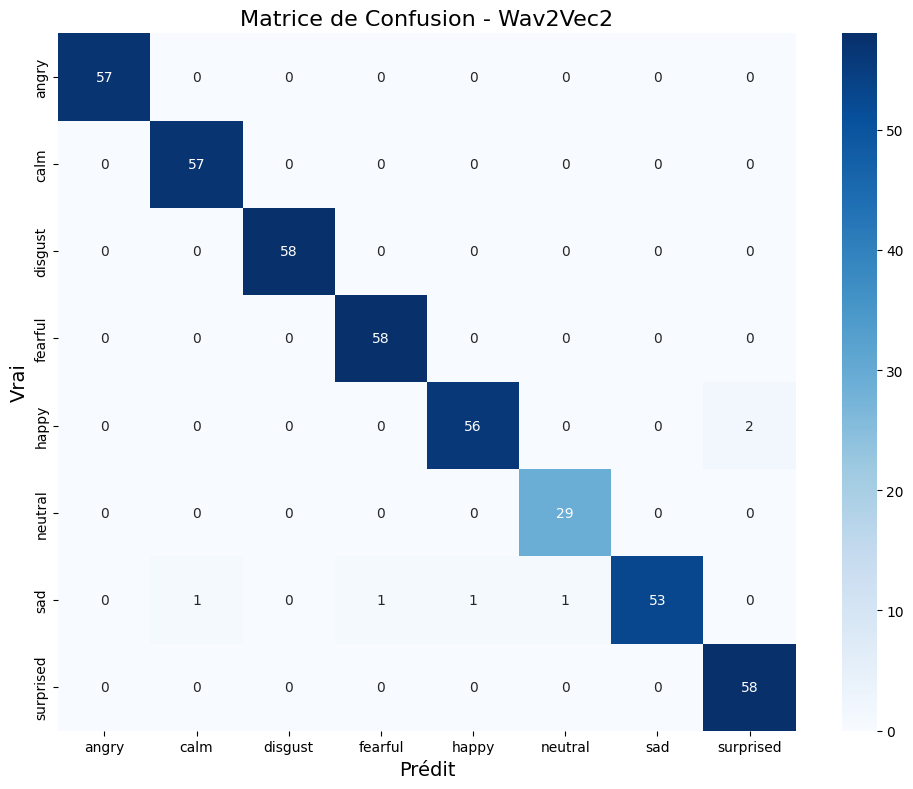


📊 Rapport de Classification - Wav2Vec2:
------------------------------------------------------------
              precision    recall  f1-score   support

       angry       1.00      1.00      1.00        57
        calm       0.98      1.00      0.99        57
     disgust       1.00      1.00      1.00        58
     fearful       0.98      1.00      0.99        58
       happy       0.98      0.97      0.97        58
     neutral       0.97      1.00      0.98        29
         sad       1.00      0.93      0.96        57
   surprised       0.97      1.00      0.98        58

    accuracy                           0.99       432
   macro avg       0.99      0.99      0.99       432
weighted avg       0.99      0.99      0.99       432

✅ Résultats Wav2Vec2 sauvegardés dans 'wav2vec_results.json'


In [36]:
print("\n📊 Évaluation du modèle Wav2Vec2 sur le jeu de test...")

test_predictions = trainer.predict(dataset_test_processed)
y_pred_wav2vec = np.argmax(test_predictions.predictions, axis=1)
y_test_wav2vec = test_predictions.label_ids

wav2vec_test_accuracy = accuracy_score(y_test_wav2vec, y_pred_wav2vec)
print(f"🎯 Accuracy sur le test (Wav2Vec2): {wav2vec_test_accuracy*100:.2f}%")

cm_wav2vec = confusion_matrix(y_test_wav2vec, y_pred_wav2vec)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_wav2vec, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder_w2v.classes_, yticklabels=label_encoder_w2v.classes_)
plt.title('Matrice de Confusion - Wav2Vec2', fontsize=16)
plt.xlabel('Prédit', fontsize=14)
plt.ylabel('Vrai', fontsize=14)
plt.tight_layout()
plt.show()

print("\n📊 Rapport de Classification - Wav2Vec2:")
print("-" * 60)
print(classification_report(y_test_wav2vec, y_pred_wav2vec, target_names=label_encoder_w2v.classes_))

wav2vec_results = {
    'model': 'Wav2Vec2',
    'accuracy': float(wav2vec_test_accuracy),
    'num_classes': num_labels,
    'classes': list(label_encoder_w2v.classes_),
    'model_name': MODEL_NAME
}
with open('wav2vec_results.json', 'w') as f:
    json.dump(wav2vec_results, f)

print("✅ Résultats Wav2Vec2 sauvegardés dans 'wav2vec_results.json'")

### C.10 Prédiction sur un exemple

In [37]:
def predict_emotion_wav2vec(file_path, model, processor, label_encoder, max_length=MAX_LENGTH, sr=SAMPLE_RATE):
    """Prédire l'émotion à partir d'un fichier audio (Wav2Vec2)"""
    try:
        audio, _ = librosa.load(file_path, sr=sr)
    except Exception as e:
        return f"❌ Erreur: Impossible de charger l'audio ({e})", 0, []

    if len(audio) > max_length:
        audio = audio[:max_length]
    elif len(audio) < max_length:
        audio = np.pad(audio, (0, max_length - len(audio)))

    inputs = processor(audio, sampling_rate=sr, return_tensors="pt", padding=True)

    model.eval()
    device = next(model.parameters()).device
    input_values = inputs['input_values'].to(device)

    with torch.no_grad():
        logits = model(input_values).logits
        probs = torch.softmax(logits, dim=-1).cpu().numpy()[0]

    emotion_idx = np.argmax(probs)
    emotion = label_encoder.classes_[emotion_idx]
    confidence = probs[emotion_idx] * 100

    results = [(name, score * 100) for name, score in zip(label_encoder.classes_, probs)]

    return emotion, confidence, results

# Tester sur un exemple
sample_file = df_wav2vec.iloc[test_idx[0]]['file_path'] if 'test_idx' in globals() else data_wav2vec[0]['file_path']
print(f"📂 Fichier test: {os.path.basename(sample_file)}")

emotion_pred, confidence, all_scores = predict_emotion_wav2vec(
    sample_file, wav2vec_model, processor, label_encoder_w2v
)
print(f"\n🔮 Prédiction Wav2Vec2: {emotion_pred} (Confiance: {confidence:.2f}%)")

print("\n📊 Scores Wav2Vec2 par émotion:")
print("-" * 40)
for emotion, score in sorted(all_scores, key=lambda x: -x[1]):
    bar = "█" * int(score / 5)
    print(f"{emotion:12} : {score:6.2f}% {bar}")

📂 Fichier test: 03-01-06-02-01-01-20.wav

🔮 Prédiction Wav2Vec2: fearful (Confiance: 99.67%)

📊 Scores Wav2Vec2 par émotion:
----------------------------------------
fearful      :  99.67% ███████████████████
surprised    :   0.09% 
happy        :   0.06% 
sad          :   0.05% 
angry        :   0.04% 
calm         :   0.03% 
disgust      :   0.03% 
neutral      :   0.02% 


### C.11 Sauvegarde du modèle Wav2Vec2

In [38]:
wav2vec_save_dir = './wav2vec2_ser_model'
wav2vec_model.save_pretrained(wav2vec_save_dir)
processor.save_pretrained(wav2vec_save_dir)
print(f"✅ Modèle Wav2Vec2 sauvegardé dans: {wav2vec_save_dir}")

with open('label_encoder_wav2vec.pkl', 'wb') as f:
    pickle.dump(label_encoder_w2v, f)
print("✅ Label encoder Wav2Vec2 sauvegardé: label_encoder_wav2vec.pkl")

wav2vec_metadata = {
    'model_type': 'Wav2Vec2',
    'base_model': MODEL_NAME,
    'num_classes': num_labels,
    'classes': list(label_encoder_w2v.classes_),
    'test_accuracy': float(wav2vec_test_accuracy),
    'sample_rate': SAMPLE_RATE,
    'max_length_seconds': MAX_LENGTH / SAMPLE_RATE,
    'learning_rate': LEARNING_RATE,
    'batch_size': BATCH_SIZE,
    'num_epochs': NUM_EPOCHS,
    'training_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'dataset': 'RAVDESS',
    'num_samples': len(data_wav2vec),
    'train_samples': len(dataset_train),
    'val_samples': len(dataset_val),
    'test_samples': len(dataset_test)
}
with open('wav2vec_metadata.json', 'w') as f:
    json.dump(wav2vec_metadata, f, indent=2)
print("✅ Métadonnées Wav2Vec2 sauvegardées: wav2vec_metadata.json")

print("\n" + "="*50)
print("🎤 PARTIE C - RÉSUMÉ Wav2Vec2")
print("="*50)
print(f"📊 Dataset: RAVDESS")
print(f"🎯 Classes: {list(label_encoder_w2v.classes_)}")
print(f"📈 Accuracy sur le test: {wav2vec_test_accuracy*100:.2f}%")
print("="*50)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Modèle Wav2Vec2 sauvegardé dans: ./wav2vec2_ser_model
✅ Label encoder Wav2Vec2 sauvegardé: label_encoder_wav2vec.pkl
✅ Métadonnées Wav2Vec2 sauvegardées: wav2vec_metadata.json

🎤 PARTIE C - RÉSUMÉ Wav2Vec2
📊 Dataset: RAVDESS
🎯 Classes: ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
📈 Accuracy sur le test: 98.61%


---
# 📊 Partie D — Comparaison finale des 3 modèles

Comparaison des performances de **CNN 2D**, **LSTM** et **Wav2Vec2** sur le même jeu de test RAVDESS.

In [39]:
# Charger les résultats des 3 modèles
with open('cnn_results.json', 'r') as f:
    cnn_results = json.load(f)

with open('lstm_results.json', 'r') as f:
    lstm_results = json.load(f)

with open('wav2vec_results.json', 'r') as f:
    wav2vec_results = json.load(f)

comparison_df = pd.DataFrame([
    {'Modèle': 'CNN 2D', 'Accuracy': cnn_results['accuracy'], 'Représentation': 'Spectrogramme Mel'},
    {'Modèle': 'LSTM', 'Accuracy': lstm_results['accuracy'], 'Représentation': 'Séquence MFCC'},
    {'Modèle': 'Wav2Vec2', 'Accuracy': wav2vec_results['accuracy'], 'Représentation': 'Audio brut (fine-tuning)'},
])
comparison_df['Accuracy (%)'] = (comparison_df['Accuracy'] * 100).round(2)

print("📊 Tableau comparatif :")
print(comparison_df[['Modèle', 'Représentation', 'Accuracy (%)']].to_string(index=False))

📊 Tableau comparatif :
  Modèle           Représentation  Accuracy (%)
  CNN 2D        Spectrogramme Mel         82.87
    LSTM            Séquence MFCC         87.04
Wav2Vec2 Audio brut (fine-tuning)         98.61


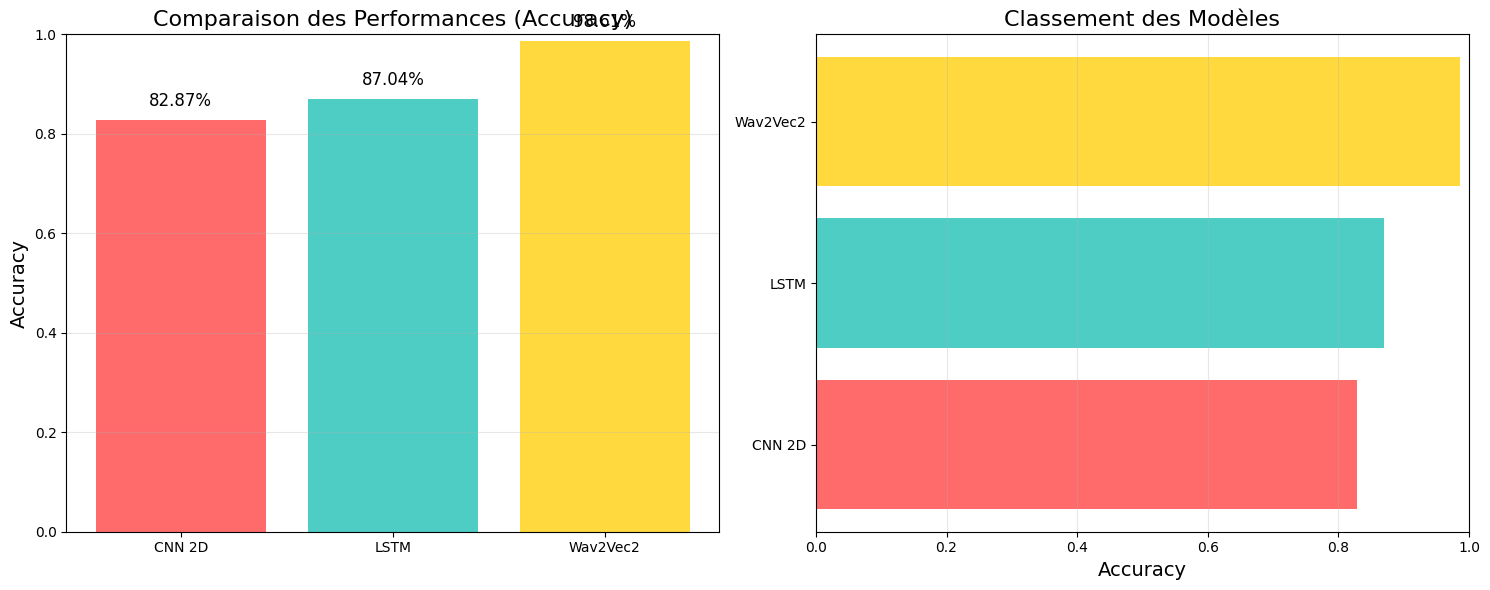


🏆 COMPARAISON FINALE CNN vs LSTM vs Wav2Vec2
Wav2Vec2   - Accuracy: 98.61%  (Audio brut (fine-tuning))
LSTM       - Accuracy: 87.04%  (Séquence MFCC)
CNN 2D     - Accuracy: 82.87%  (Spectrogramme Mel)
🏆 Meilleur modèle: Wav2Vec2 avec 98.61%


In [40]:
# Graphique de comparaison
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = ['#FF6B6B', '#4ECDC4', '#FFD93D']
models_names = comparison_df['Modèle'].tolist()
accuracies = comparison_df['Accuracy'].tolist()

bars = axes[0].bar(models_names, accuracies, color=colors)
axes[0].set_title('Comparaison des Performances (Accuracy)', fontsize=16)
axes[0].set_ylabel('Accuracy', fontsize=14)
axes[0].set_ylim(0, 1)
axes[0].grid(axis='y', alpha=0.3)

for bar, acc in zip(bars, accuracies):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{acc*100:.2f}%', ha='center', va='bottom', fontsize=12)

# Classement
sorted_df = comparison_df.sort_values('Accuracy', ascending=True)
axes[1].barh(sorted_df['Modèle'], sorted_df['Accuracy'], color=[colors[models_names.index(m)] for m in sorted_df['Modèle']])
axes[1].set_title('Classement des Modèles', fontsize=16)
axes[1].set_xlabel('Accuracy', fontsize=14)
axes[1].set_xlim(0, 1)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "="*50)
print("🏆 COMPARAISON FINALE CNN vs LSTM vs Wav2Vec2")
print("="*50)
for _, row in comparison_df.sort_values('Accuracy', ascending=False).iterrows():
    print(f"{row['Modèle']:10} - Accuracy: {row['Accuracy']*100:.2f}%  ({row['Représentation']})")
print("="*50)

best_model_row = comparison_df.loc[comparison_df['Accuracy'].idxmax()]
print(f"🏆 Meilleur modèle: {best_model_row['Modèle']} avec {best_model_row['Accuracy']*100:.2f}%")

---
# 🎛️ Partie E — Interface interactive (Gradio)

Démo audio en temps réel : l'utilisateur enregistre ou téléverse un extrait audio, et les **trois modèles** prédisent l'émotion en parallèle, avec un tableau comparatif.

> ℹ️ Cette section suppose que les trois modèles (`cnn_model`, `lstm_model`, `wav2vec_model`) et leurs encodeurs de labels sont encore en mémoire (exécution complète du notebook de haut en bas). Sinon, ils sont rechargés automatiquement depuis les fichiers sauvegardés.

In [41]:
import gradio as gr

# --- Rechargement défensif des modèles/encodeurs si nécessaire ---

if 'cnn_model' not in globals():
    print("🔄 Rechargement du modèle CNN depuis le disque...")
    cnn_model = tf.keras.models.load_model('cnn_ser_model.h5')
    with open('label_encoder.pkl', 'rb') as f:
        label_encoder = pickle.load(f)

if 'lstm_model' not in globals():
    print("🔄 Rechargement du modèle LSTM depuis le disque...")
    lstm_model = tf.keras.models.load_model('lstm_ser_model.h5')
    with open('label_encoder_lstm.pkl', 'rb') as f:
        label_encoder_lstm = pickle.load(f)
    with open('lstm_metadata.json', 'r') as f:
        max_seq_len = json.load(f)['sequence_length']

if 'wav2vec_model' not in globals():
    print("🔄 Rechargement du modèle Wav2Vec2 depuis le disque...")
    wav2vec_model = Wav2Vec2ForSequenceClassification.from_pretrained('./wav2vec2_ser_model')
    processor = Wav2Vec2Processor.from_pretrained('./wav2vec2_ser_model')
    with open('label_encoder_wav2vec.pkl', 'rb') as f:
        label_encoder_w2v = pickle.load(f)

EMOTION_EMOJIS = {
    'neutral': '😐', 'calm': '😌', 'happy': '😄', 'sad': '😢',
    'angry': '😠', 'fearful': '😨', 'disgust': '🤢', 'surprised': '😲'
}


def predict_all_models(audio_path):
    """Exécute les 3 modèles sur un fichier audio et renvoie un résumé comparatif."""
    if audio_path is None:
        return "⚠️ Veuillez fournir un fichier audio.", None, None, None

    # --- CNN ---
    try:
        cnn_emotion, cnn_conf, cnn_scores = predict_emotion_cnn(audio_path, cnn_model, label_encoder)
    except Exception as e:
        cnn_emotion, cnn_conf, cnn_scores = f"Erreur: {e}", 0, []

    # --- LSTM ---
    try:
        lstm_emotion, lstm_conf, lstm_scores = predict_emotion_lstm(
            audio_path, lstm_model, label_encoder_lstm, max_seq_len
        )
    except Exception as e:
        lstm_emotion, lstm_conf, lstm_scores = f"Erreur: {e}", 0, []

    # --- Wav2Vec2 ---
    try:
        w2v_emotion, w2v_conf, w2v_scores = predict_emotion_wav2vec(
            audio_path, wav2vec_model, processor, label_encoder_w2v
        )
    except Exception as e:
        w2v_emotion, w2v_conf, w2v_scores = f"Erreur: {e}", 0, []

    # Résumé textuel
    summary = f"""
### 🔮 Résultats de la prédiction

| Modèle | Émotion prédite | Confiance |
|---|---|---|
| **CNN 2D** | {EMOTION_EMOJIS.get(cnn_emotion, '')} {cnn_emotion} | {cnn_conf:.1f}% |
| **LSTM** | {EMOTION_EMOJIS.get(lstm_emotion, '')} {lstm_emotion} | {lstm_conf:.1f}% |
| **Wav2Vec2** | {EMOTION_EMOJIS.get(w2v_emotion, '')} {w2v_emotion} | {w2v_conf:.1f}% |
"""

    # Graphique comparatif des scores par émotion pour les 3 modèles
    fig, ax = plt.subplots(figsize=(10, 5))
    all_emotions = sorted(set([e for e, _ in cnn_scores] + [e for e, _ in lstm_scores] + [e for e, _ in w2v_scores]))

    def scores_dict(scores):
        return {e: s for e, s in scores}

    cnn_d, lstm_d, w2v_d = scores_dict(cnn_scores), scores_dict(lstm_scores), scores_dict(w2v_scores)

    x = np.arange(len(all_emotions))
    width = 0.25
    ax.bar(x - width, [cnn_d.get(e, 0) for e in all_emotions], width, label='CNN', color='#FF6B6B')
    ax.bar(x, [lstm_d.get(e, 0) for e in all_emotions], width, label='LSTM', color='#4ECDC4')
    ax.bar(x + width, [w2v_d.get(e, 0) for e in all_emotions], width, label='Wav2Vec2', color='#FFD93D')
    ax.set_xticks(x)
    ax.set_xticklabels(all_emotions, rotation=45)
    ax.set_ylabel('Confiance (%)')
    ax.set_title('Comparaison des scores par émotion et par modèle')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()

    return summary, f"{EMOTION_EMOJIS.get(cnn_emotion,'')} {cnn_emotion} ({cnn_conf:.1f}%)", \
           f"{EMOTION_EMOJIS.get(lstm_emotion,'')} {lstm_emotion} ({lstm_conf:.1f}%)", fig


with gr.Blocks(title="SER - Reconnaissance des Émotions Vocales") as demo:
    gr.Markdown("# 🎤 Reconnaissance des Émotions Vocales — Démo comparative")
    gr.Markdown(
        "Enregistrez ou téléversez un extrait audio (voix) pour comparer les prédictions "
        "des modèles **CNN 2D**, **LSTM** et **Wav2Vec2** entraînés sur RAVDESS."
    )

    with gr.Row():
        audio_input = gr.Audio(sources=["microphone", "upload"], type="filepath", label="🎙️ Audio d'entrée")

    predict_btn = gr.Button("🔮 Prédire l'émotion", variant="primary")

    with gr.Row():
        cnn_output = gr.Textbox(label="CNN 2D")
        lstm_output = gr.Textbox(label="LSTM")

    summary_output = gr.Markdown(label="Résumé")
    plot_output = gr.Plot(label="Comparaison des scores par émotion")

    predict_btn.click(
        fn=predict_all_models,
        inputs=audio_input,
        outputs=[summary_output, cnn_output, lstm_output, plot_output]
    )

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c3fceb94e783f3c1fe.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## ✅ Conclusion

Ce notebook a permis d'entraîner et de comparer trois approches de reconnaissance des émotions vocales sur RAVDESS :

- **CNN 2D** sur spectrogrammes Mel
- **LSTM** sur séquences MFCC
- **Wav2Vec2** fine-tuné sur audio brut

Les résultats détaillés (accuracy, matrices de confusion, rapports de classification) sont disponibles dans la **Partie D**, et une démo interactive est fournie dans la **Partie E**.

**Livrables générés par ce notebook :**
- Modèles sauvegardés : `cnn_ser_model.h5`, `lstm_ser_model.h5`, `./wav2vec2_ser_model/`
- Résultats : `cnn_results.json`, `lstm_results.json`, `wav2vec_results.json`
- Métadonnées et historiques d'entraînement pour chaque modèle
- Interface Gradio pour la démo audio en temps réel
